
Training models on fused_pca features...

Training RandomForest on fused_pca...
Accuracy (RandomForest on fused_pca): 1.0000
               precision    recall  f1-score   support

  freshapples       1.00      1.00      1.00        23
  freshbanana       1.00      1.00      1.00        20
 freshoranges       1.00      1.00      1.00        19
 rottenapples       1.00      1.00      1.00        17
 rottenbanana       1.00      1.00      1.00        17
rottenoranges       1.00      1.00      1.00        24

     accuracy                           1.00       120
    macro avg       1.00      1.00      1.00       120
 weighted avg       1.00      1.00      1.00       120


Training XGBoost on fused_pca...


c:\Users\Asus\Documents\FRUIT CLASSIFICATION PROJECT\venv\Lib\site-packages\xgboost\core.py:158: UserWarning: [13:10:50] WARNING: C:\buildkite-agent\builds\buildkite-windows-cpu-autoscaling-group-i-08cbc0333d8d4aae1-1\xgboost\xgboost-ci-windows\src\learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)


Accuracy (XGBoost on fused_pca): 0.9917
               precision    recall  f1-score   support

  freshapples       1.00      1.00      1.00        23
  freshbanana       0.95      1.00      0.98        20
 freshoranges       1.00      1.00      1.00        19
 rottenapples       1.00      1.00      1.00        17
 rottenbanana       1.00      1.00      1.00        17
rottenoranges       1.00      0.96      0.98        24

     accuracy                           0.99       120
    macro avg       0.99      0.99      0.99       120
 weighted avg       0.99      0.99      0.99       120


Training models on combined_pca features...

Training RandomForest on combined_pca...
Accuracy (RandomForest on combined_pca): 0.9083
               precision    recall  f1-score   support

  freshapples       0.96      1.00      0.98        23
  freshbanana       1.00      1.00      1.00        20
 freshoranges       0.84      0.84      0.84        19
 rottenapples       0.94      1.00      0.97       

c:\Users\Asus\Documents\FRUIT CLASSIFICATION PROJECT\venv\Lib\site-packages\xgboost\core.py:158: UserWarning: [13:10:52] WARNING: C:\buildkite-agent\builds\buildkite-windows-cpu-autoscaling-group-i-08cbc0333d8d4aae1-1\xgboost\xgboost-ci-windows\src\learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)


Accuracy (XGBoost on combined_pca): 0.9833
               precision    recall  f1-score   support

  freshapples       1.00      1.00      1.00        23
  freshbanana       1.00      0.90      0.95        20
 freshoranges       1.00      1.00      1.00        19
 rottenapples       0.89      1.00      0.94        17
 rottenbanana       1.00      1.00      1.00        17
rottenoranges       1.00      1.00      1.00        24

     accuracy                           0.98       120
    macro avg       0.98      0.98      0.98       120
 weighted avg       0.99      0.98      0.98       120


Displaying predictions for fused_pca...


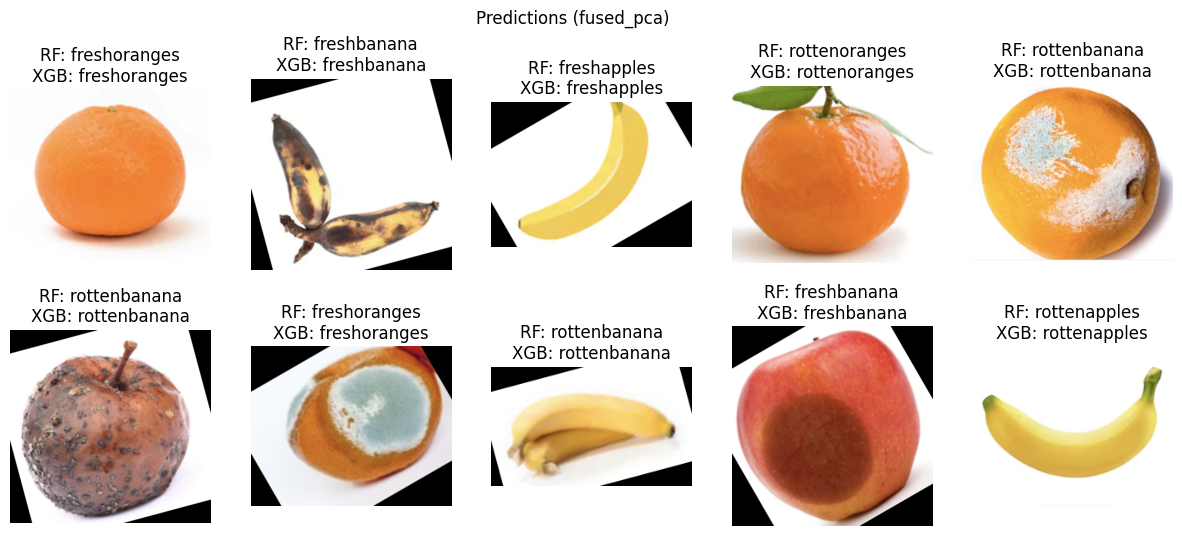


Displaying predictions for combined_pca...


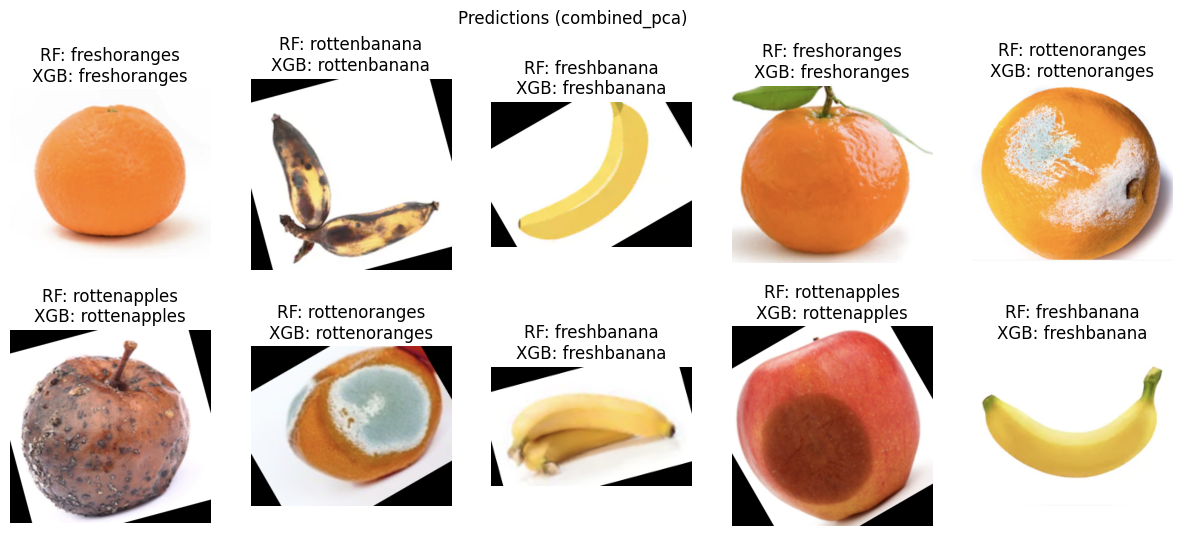


ML model training, evaluation, and image prediction display complete!


In [1]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import os
import pandas as pd
import cv2
import random

# Define class labels
class_labels = ["freshapples", "freshbanana", "freshoranges", "rottenapples", "rottenbanana", "rottenoranges"]

# Models to use
models = {
    "RandomForest": RandomForestClassifier(n_estimators=100, random_state=42),
    "XGBoost": XGBClassifier(use_label_encoder=False, eval_metric='mlogloss')
}

# Store results for comparison
results = []

# Dictionary to store image predictions
image_predictions = {"fused_pca": [], "combined_pca": []}

# Train and evaluate models for both fused PCA and combined PCA
for pca_type in ["fused_pca", "combined_pca"]:
    print(f"\nTraining models on {pca_type} features...")
    
    # Load and prepare data
    X, y, image_paths = [], [], []
    for class_idx, class_name in enumerate(class_labels):
        feature_filename = f"efficient_{class_name}_{pca_type}_final.npy"
        image_folder = f"./dataset/test/{class_name}"  # Update with your actual image directory
       
        if not os.path.exists(feature_filename):
            print(f"Skipping {class_name}, file not found: {feature_filename}")
            continue
        
        features = np.load(feature_filename)
        image_files = sorted(os.listdir(image_folder))[:len(features)]  # Match features count
        
        X.append(features)
        y.extend([class_idx] * len(features))
        image_paths.extend([os.path.join(image_folder, img) for img in image_files])
    
    # Convert to numpy arrays
    X = np.vstack(X)
    y = np.array(y)
    
    # Split data
    X_train, X_test, y_train, y_test, image_paths_train, image_paths_test = train_test_split(
        X, y, image_paths, test_size=0.2, random_state=42
    )
    
    # Select 10 random images for prediction display
    sample_indices = random.sample(range(len(X_test)), 10)
    X_sample = X_test[sample_indices]
    y_sample = y_test[sample_indices]
    image_sample_paths = [image_paths_test[i] for i in sample_indices]
    
    # Train and evaluate each model
    for model_name, model in models.items():
        print(f"\nTraining {model_name} on {pca_type}...")
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
        
        # Evaluate performance
        acc = accuracy_score(y_test, y_pred)
        class_report = classification_report(y_test, y_pred, target_names=class_labels, output_dict=True)
        conf_matrix = confusion_matrix(y_test, y_pred)
        
        # Store results
        results.append({
            "Model": model_name,
            "PCA Type": pca_type,
            "Accuracy": acc,
            "Precision": {label: class_report[label]["precision"] for label in class_labels},
            "Recall": {label: class_report[label]["recall"] for label in class_labels},
            "F1-score": {label: class_report[label]["f1-score"] for label in class_labels},
            "Confusion Matrix": conf_matrix
        })
        
        # Print evaluation metrics
        print(f"Accuracy ({model_name} on {pca_type}): {acc:.4f}")
        print(classification_report(y_test, y_pred, target_names=class_labels))
        
        # Store predictions for sample images
        y_sample_pred = model.predict(X_sample)
        image_predictions[pca_type].append((model_name, y_sample_pred))

# Display images with predictions
for pca_type in ["fused_pca", "combined_pca"]:
    print(f"\nDisplaying predictions for {pca_type}...")
    plt.figure(figsize=(15, 6))
    for idx, img_path in enumerate(image_sample_paths):
        img = cv2.imread(img_path)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        
        rf_pred = class_labels[image_predictions[pca_type][0][1][idx]]  # RandomForest prediction
        xgb_pred = class_labels[image_predictions[pca_type][1][1][idx]]  # XGBoost prediction
        
        plt.subplot(2, 5, idx + 1)
        plt.imshow(img)
        plt.axis("off")
        plt.title(f"RF: {rf_pred}\nXGB: {xgb_pred}")
    plt.suptitle(f"Predictions ({pca_type})")
    plt.show()

print("\nML model training, evaluation, and image prediction display complete!")

In [1]:
pip install shap


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 25.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import shap


c:\Users\Asus\Documents\FRUIT CLASSIFICATION PROJECT\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm



Training models on fused_pca features...

Training RandomForest on fused_pca...

Explaining with SHAP for RandomForest on fused_pca...


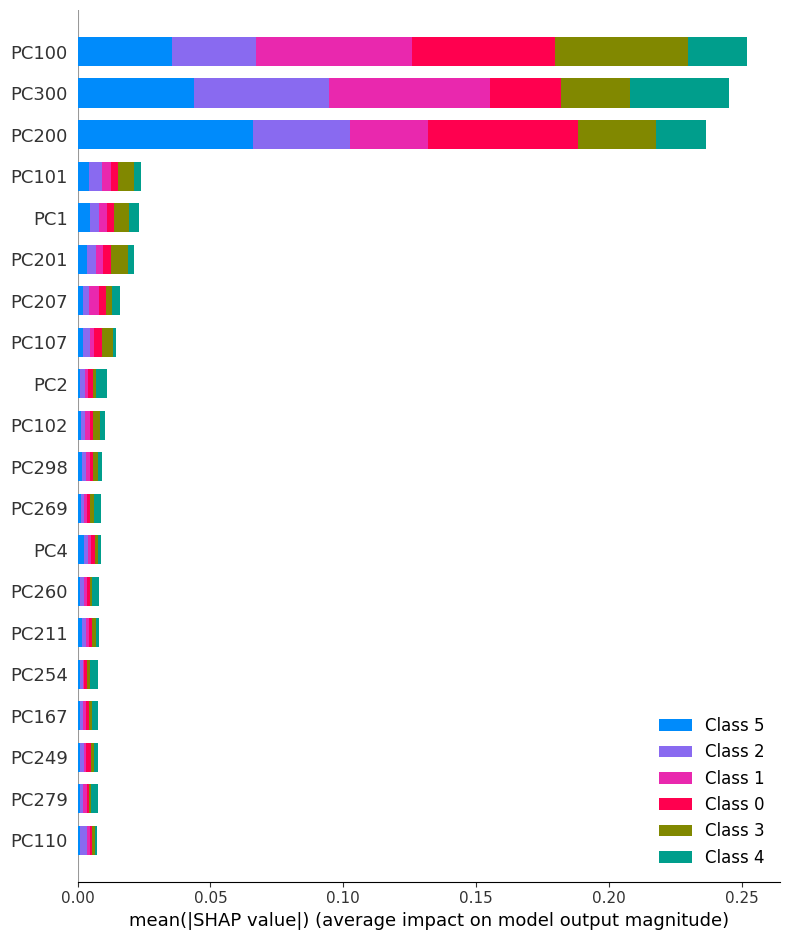

Accuracy (RandomForest on fused_pca): 1.0000
               precision    recall  f1-score   support

  freshapples       1.00      1.00      1.00        23
  freshbanana       1.00      1.00      1.00        20
 freshoranges       1.00      1.00      1.00        19
 rottenapples       1.00      1.00      1.00        17
 rottenbanana       1.00      1.00      1.00        17
rottenoranges       1.00      1.00      1.00        24

     accuracy                           1.00       120
    macro avg       1.00      1.00      1.00       120
 weighted avg       1.00      1.00      1.00       120


Training XGBoost on fused_pca...


c:\Users\Asus\Documents\FRUIT CLASSIFICATION PROJECT\venv\Lib\site-packages\xgboost\core.py:158: UserWarning: [16:11:47] WARNING: C:\buildkite-agent\builds\buildkite-windows-cpu-autoscaling-group-i-08cbc0333d8d4aae1-1\xgboost\xgboost-ci-windows\src\learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)



Explaining with SHAP for XGBoost on fused_pca...


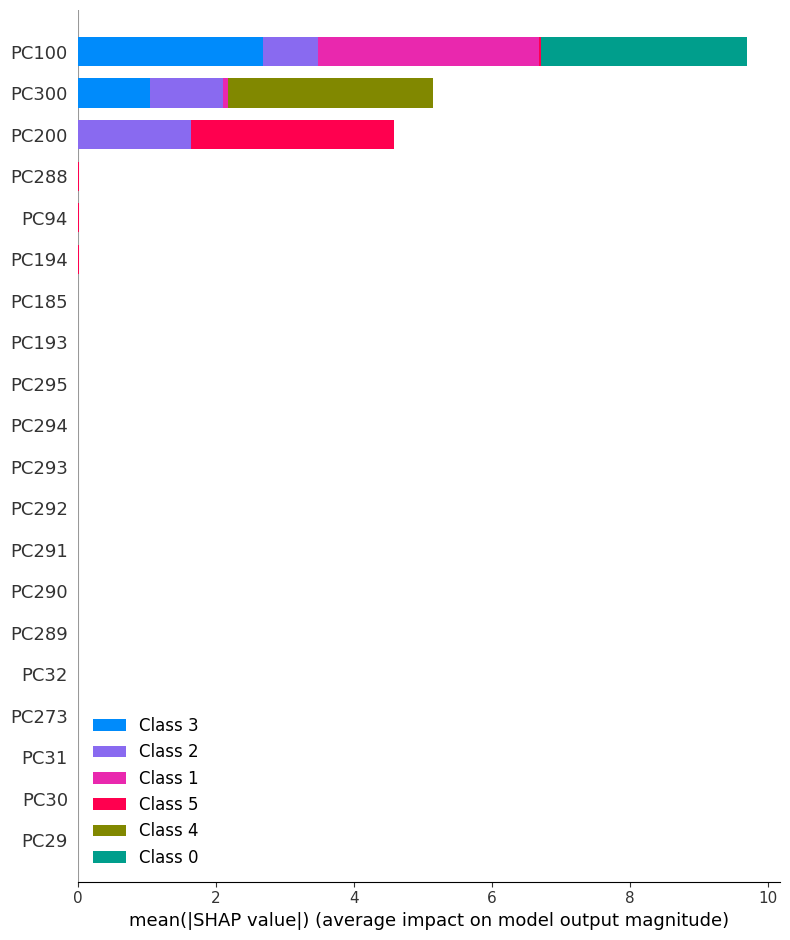

Accuracy (XGBoost on fused_pca): 0.9917
               precision    recall  f1-score   support

  freshapples       1.00      1.00      1.00        23
  freshbanana       0.95      1.00      0.98        20
 freshoranges       1.00      1.00      1.00        19
 rottenapples       1.00      1.00      1.00        17
 rottenbanana       1.00      1.00      1.00        17
rottenoranges       1.00      0.96      0.98        24

     accuracy                           0.99       120
    macro avg       0.99      0.99      0.99       120
 weighted avg       0.99      0.99      0.99       120


Training models on combined_pca features...

Training RandomForest on combined_pca...

Explaining with SHAP for RandomForest on combined_pca...


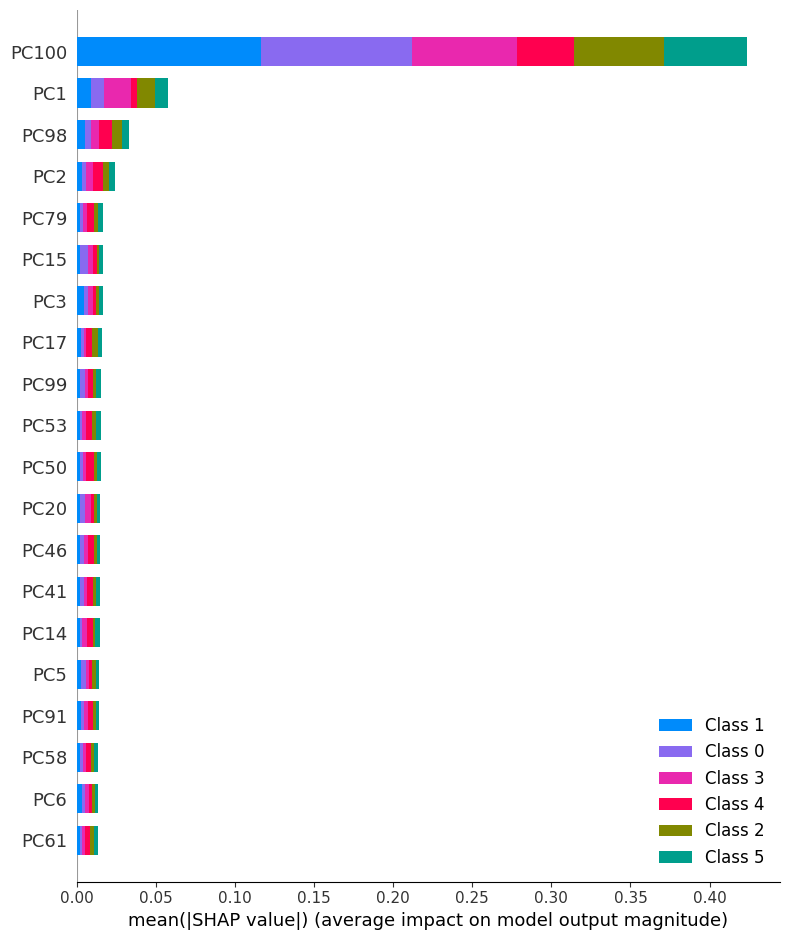

Accuracy (RandomForest on combined_pca): 0.9083
               precision    recall  f1-score   support

  freshapples       0.96      1.00      0.98        23
  freshbanana       1.00      1.00      1.00        20
 freshoranges       0.84      0.84      0.84        19
 rottenapples       0.94      1.00      0.97        17
 rottenbanana       0.83      0.88      0.86        17
rottenoranges       0.86      0.75      0.80        24

     accuracy                           0.91       120
    macro avg       0.91      0.91      0.91       120
 weighted avg       0.91      0.91      0.91       120


Training XGBoost on combined_pca...


c:\Users\Asus\Documents\FRUIT CLASSIFICATION PROJECT\venv\Lib\site-packages\xgboost\core.py:158: UserWarning: [16:11:51] WARNING: C:\buildkite-agent\builds\buildkite-windows-cpu-autoscaling-group-i-08cbc0333d8d4aae1-1\xgboost\xgboost-ci-windows\src\learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)



Explaining with SHAP for XGBoost on combined_pca...


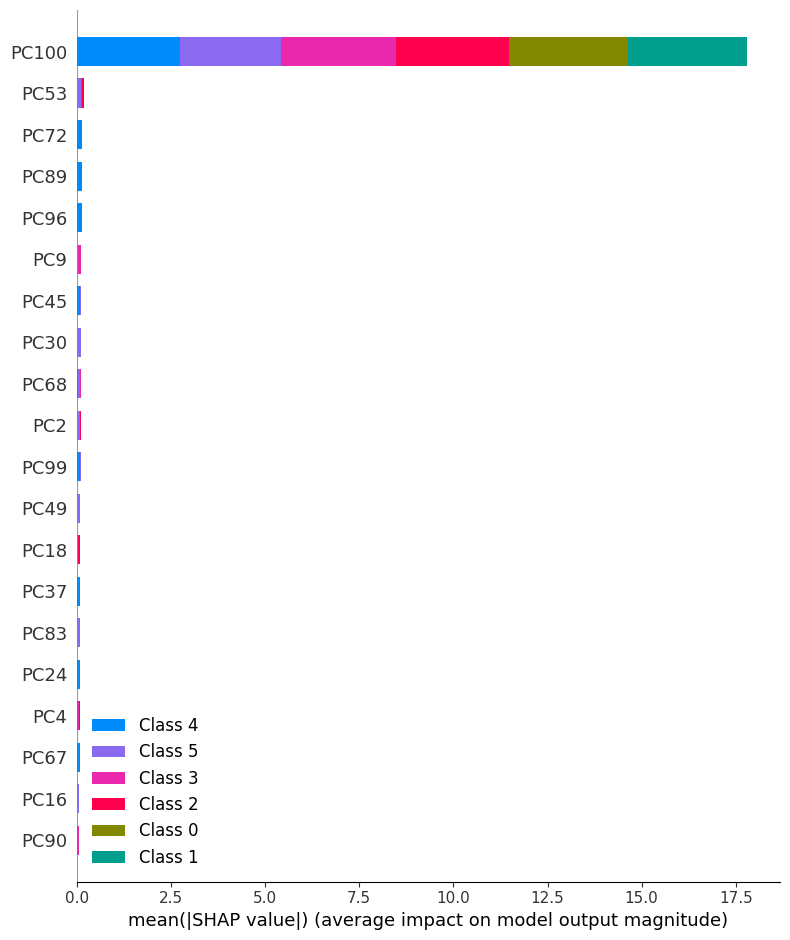

Accuracy (XGBoost on combined_pca): 0.9833
               precision    recall  f1-score   support

  freshapples       1.00      1.00      1.00        23
  freshbanana       1.00      0.90      0.95        20
 freshoranges       1.00      1.00      1.00        19
 rottenapples       0.89      1.00      0.94        17
 rottenbanana       1.00      1.00      1.00        17
rottenoranges       1.00      1.00      1.00        24

     accuracy                           0.98       120
    macro avg       0.98      0.98      0.98       120
 weighted avg       0.99      0.98      0.98       120


Displaying predictions for fused_pca...


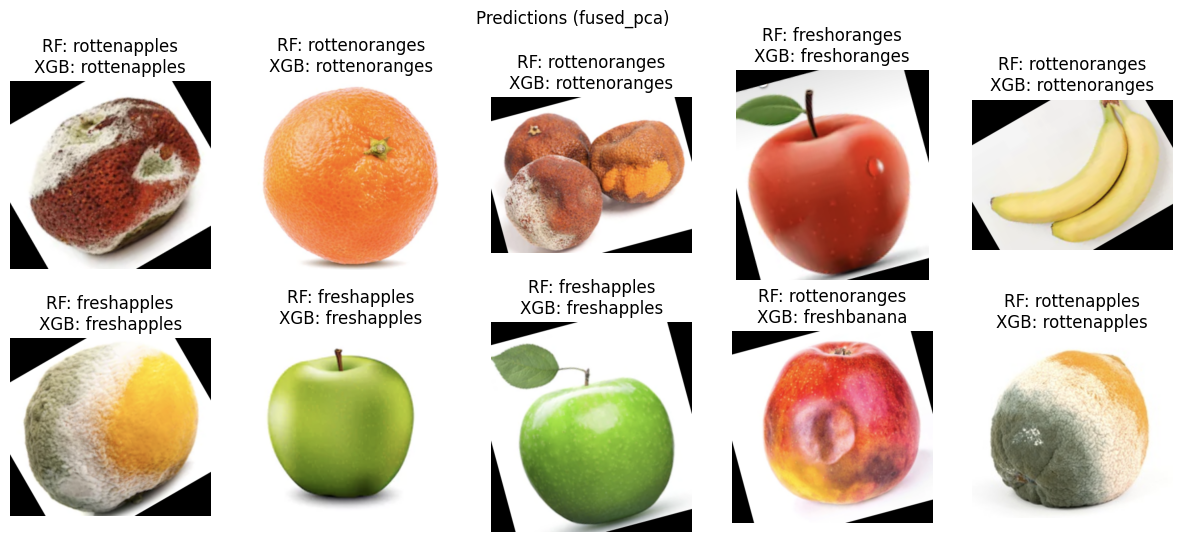


Displaying predictions for combined_pca...


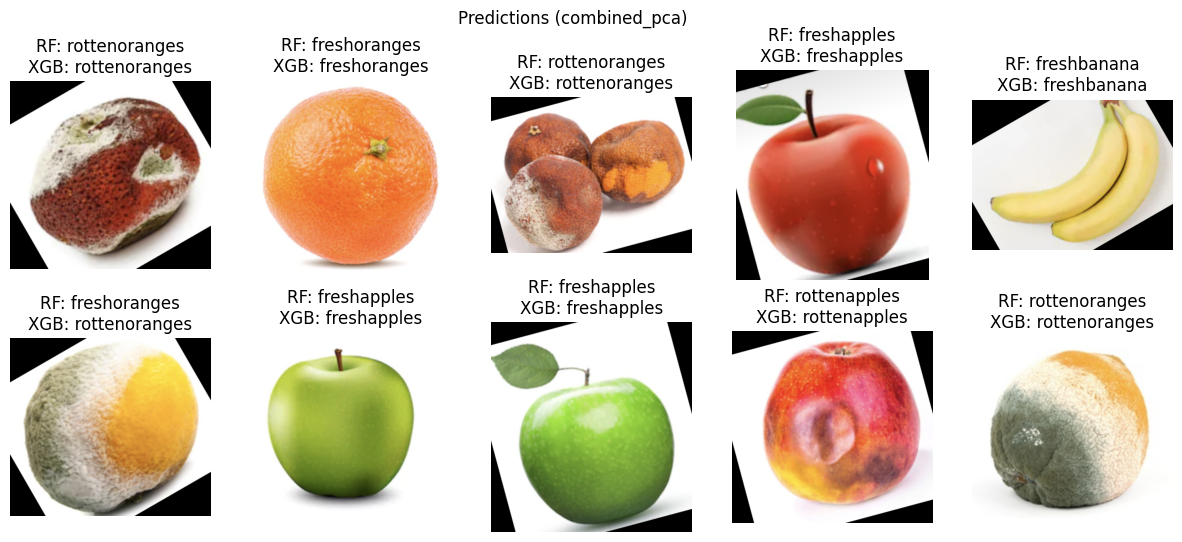


ML model training, evaluation, SHAP explainability, and image prediction display complete!


In [3]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import os
import pandas as pd
import cv2
import random
import shap

# Define class labels
class_labels = ["freshapples", "freshbanana", "freshoranges", "rottenapples", "rottenbanana", "rottenoranges"]

# Models to use
models = {
    "RandomForest": RandomForestClassifier(n_estimators=100, random_state=42),
    "XGBoost": XGBClassifier(use_label_encoder=False, eval_metric='mlogloss')
}

# Store results for comparison
results = []

# Dictionary to store image predictions
image_predictions = {"fused_pca": [], "combined_pca": []}

# Train and evaluate models for both fused PCA and combined PCA
for pca_type in ["fused_pca", "combined_pca"]:
    print(f"\nTraining models on {pca_type} features...")
    
    # Load and prepare data
    X, y, image_paths = [], [], []
    for class_idx, class_name in enumerate(class_labels):
        feature_filename = f"efficient_{class_name}_{pca_type}_final.npy"
        image_folder = f"./dataset/test/{class_name}"  # Update with your actual image directory
       
        if not os.path.exists(feature_filename):
            print(f"Skipping {class_name}, file not found: {feature_filename}")
            continue
        
        features = np.load(feature_filename)
        image_files = sorted(os.listdir(image_folder))[:len(features)]  # Match features count
        
        X.append(features)
        y.extend([class_idx] * len(features))
        image_paths.extend([os.path.join(image_folder, img) for img in image_files])
    
    # Convert to numpy arrays
    X = np.vstack(X)
    y = np.array(y)
    
    # Split data
    X_train, X_test, y_train, y_test, image_paths_train, image_paths_test = train_test_split(
        X, y, image_paths, test_size=0.2, random_state=42
    )
    
    # Select 10 random images for prediction display
    sample_indices = random.sample(range(len(X_test)), 10)
    X_sample = X_test[sample_indices]
    y_sample = y_test[sample_indices]
    image_sample_paths = [image_paths_test[i] for i in sample_indices]
    
    # Train and evaluate each model
    for model_name, model in models.items():
        print(f"\nTraining {model_name} on {pca_type}...")
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
        
        # Evaluate performance
        acc = accuracy_score(y_test, y_pred)
        class_report = classification_report(y_test, y_pred, target_names=class_labels, output_dict=True)
        conf_matrix = confusion_matrix(y_test, y_pred)
        
        # SHAP Explainability
        print(f"\nExplaining with SHAP for {model_name} on {pca_type}...")
        try:
            if model_name == "RandomForest":
                explainer = shap.TreeExplainer(model)
            elif model_name == "XGBoost":
                explainer = shap.Explainer(model)
            
            shap_values = explainer(X_test)
            feature_names = [f'PC{i+1}' for i in range(X.shape[1])]
            shap.summary_plot(shap_values, features=X_test, feature_names=feature_names, plot_type="bar")
        except Exception as e:
            print(f"SHAP failed for {model_name} on {pca_type}: {e}")
        
        # Store results
        results.append({
            "Model": model_name,
            "PCA Type": pca_type,
            "Accuracy": acc,
            "Precision": {label: class_report[label]["precision"] for label in class_labels},
            "Recall": {label: class_report[label]["recall"] for label in class_labels},
            "F1-score": {label: class_report[label]["f1-score"] for label in class_labels},
            "Confusion Matrix": conf_matrix
        })
        
        # Print evaluation metrics
        print(f"Accuracy ({model_name} on {pca_type}): {acc:.4f}")
        print(classification_report(y_test, y_pred, target_names=class_labels))
        
        # Store predictions for sample images
        y_sample_pred = model.predict(X_sample)
        image_predictions[pca_type].append((model_name, y_sample_pred))

# Display images with predictions
for pca_type in ["fused_pca", "combined_pca"]:
    print(f"\nDisplaying predictions for {pca_type}...")
    plt.figure(figsize=(15, 6))
    for idx, img_path in enumerate(image_sample_paths):
        img = cv2.imread(img_path)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        
        rf_pred = class_labels[image_predictions[pca_type][0][1][idx]]  # RandomForest prediction
        xgb_pred = class_labels[image_predictions[pca_type][1][1][idx]]  # XGBoost prediction
        
        plt.subplot(2, 5, idx + 1)
        plt.imshow(img)
        plt.axis("off")
        plt.title(f"RF: {rf_pred}\nXGB: {xgb_pred}")
    plt.suptitle(f"Predictions ({pca_type})")
    plt.show()

print("\nML model training, evaluation, SHAP explainability, and image prediction display complete!")



Training models on fused_pca features...

Training RandomForest on fused_pca...

Explaining Top 5 features with SHAP for RandomForest on fused_pca...


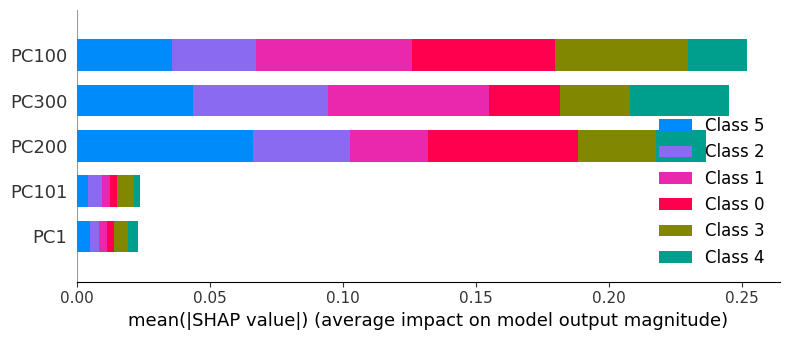

Accuracy (RandomForest on fused_pca): 1.0000
               precision    recall  f1-score   support

  freshapples       1.00      1.00      1.00        23
  freshbanana       1.00      1.00      1.00        20
 freshoranges       1.00      1.00      1.00        19
 rottenapples       1.00      1.00      1.00        17
 rottenbanana       1.00      1.00      1.00        17
rottenoranges       1.00      1.00      1.00        24

     accuracy                           1.00       120
    macro avg       1.00      1.00      1.00       120
 weighted avg       1.00      1.00      1.00       120


Training XGBoost on fused_pca...


c:\Users\Asus\Documents\FRUIT CLASSIFICATION PROJECT\venv\Lib\site-packages\xgboost\core.py:158: UserWarning: [16:14:49] WARNING: C:\buildkite-agent\builds\buildkite-windows-cpu-autoscaling-group-i-08cbc0333d8d4aae1-1\xgboost\xgboost-ci-windows\src\learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)



Explaining Top 5 features with SHAP for XGBoost on fused_pca...


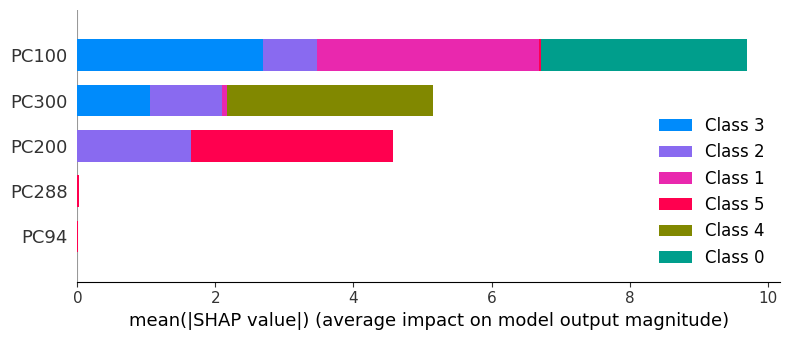

Accuracy (XGBoost on fused_pca): 0.9917
               precision    recall  f1-score   support

  freshapples       1.00      1.00      1.00        23
  freshbanana       0.95      1.00      0.98        20
 freshoranges       1.00      1.00      1.00        19
 rottenapples       1.00      1.00      1.00        17
 rottenbanana       1.00      1.00      1.00        17
rottenoranges       1.00      0.96      0.98        24

     accuracy                           0.99       120
    macro avg       0.99      0.99      0.99       120
 weighted avg       0.99      0.99      0.99       120


Training models on combined_pca features...

Training RandomForest on combined_pca...

Explaining Top 5 features with SHAP for RandomForest on combined_pca...


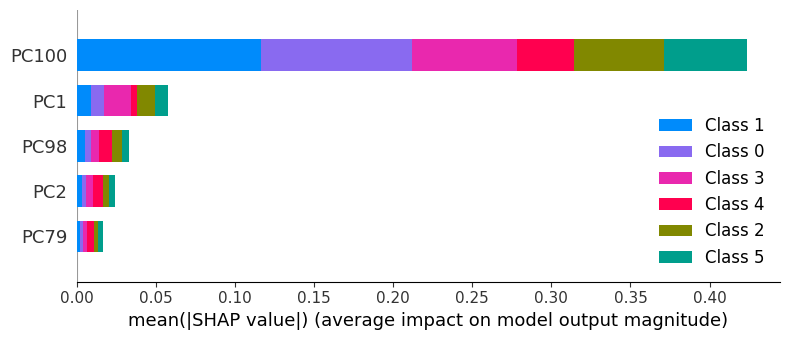

Accuracy (RandomForest on combined_pca): 0.9083
               precision    recall  f1-score   support

  freshapples       0.96      1.00      0.98        23
  freshbanana       1.00      1.00      1.00        20
 freshoranges       0.84      0.84      0.84        19
 rottenapples       0.94      1.00      0.97        17
 rottenbanana       0.83      0.88      0.86        17
rottenoranges       0.86      0.75      0.80        24

     accuracy                           0.91       120
    macro avg       0.91      0.91      0.91       120
 weighted avg       0.91      0.91      0.91       120


Training XGBoost on combined_pca...


c:\Users\Asus\Documents\FRUIT CLASSIFICATION PROJECT\venv\Lib\site-packages\xgboost\core.py:158: UserWarning: [16:14:52] WARNING: C:\buildkite-agent\builds\buildkite-windows-cpu-autoscaling-group-i-08cbc0333d8d4aae1-1\xgboost\xgboost-ci-windows\src\learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)



Explaining Top 5 features with SHAP for XGBoost on combined_pca...


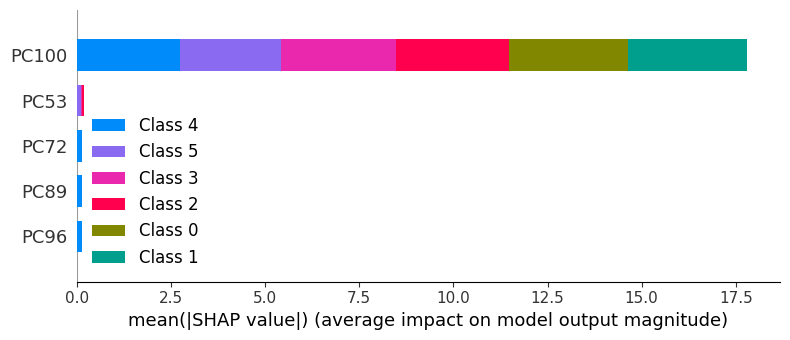

Accuracy (XGBoost on combined_pca): 0.9833
               precision    recall  f1-score   support

  freshapples       1.00      1.00      1.00        23
  freshbanana       1.00      0.90      0.95        20
 freshoranges       1.00      1.00      1.00        19
 rottenapples       0.89      1.00      0.94        17
 rottenbanana       1.00      1.00      1.00        17
rottenoranges       1.00      1.00      1.00        24

     accuracy                           0.98       120
    macro avg       0.98      0.98      0.98       120
 weighted avg       0.99      0.98      0.98       120


Displaying predictions for fused_pca...


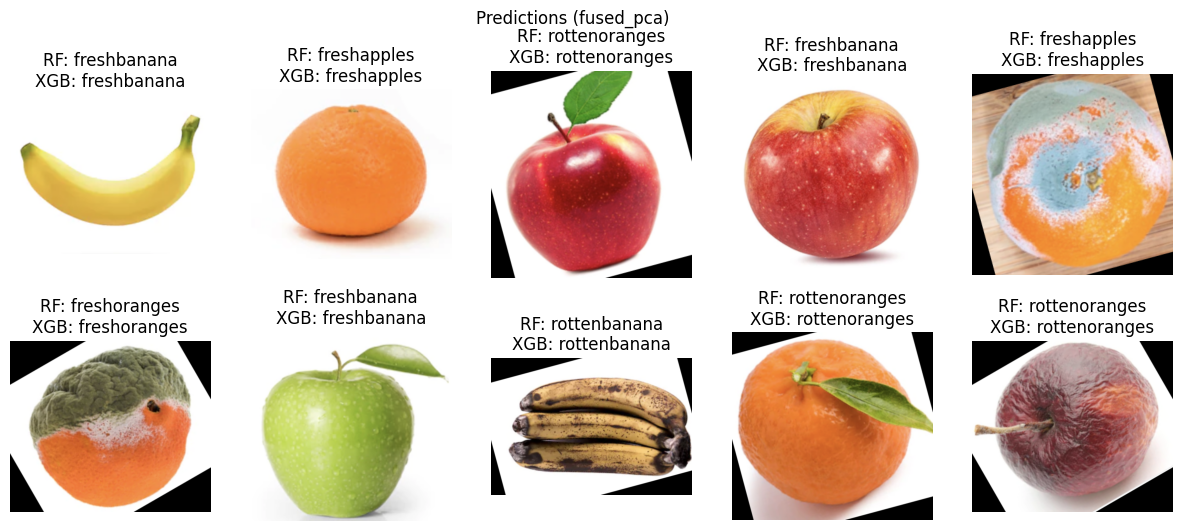


Displaying predictions for combined_pca...


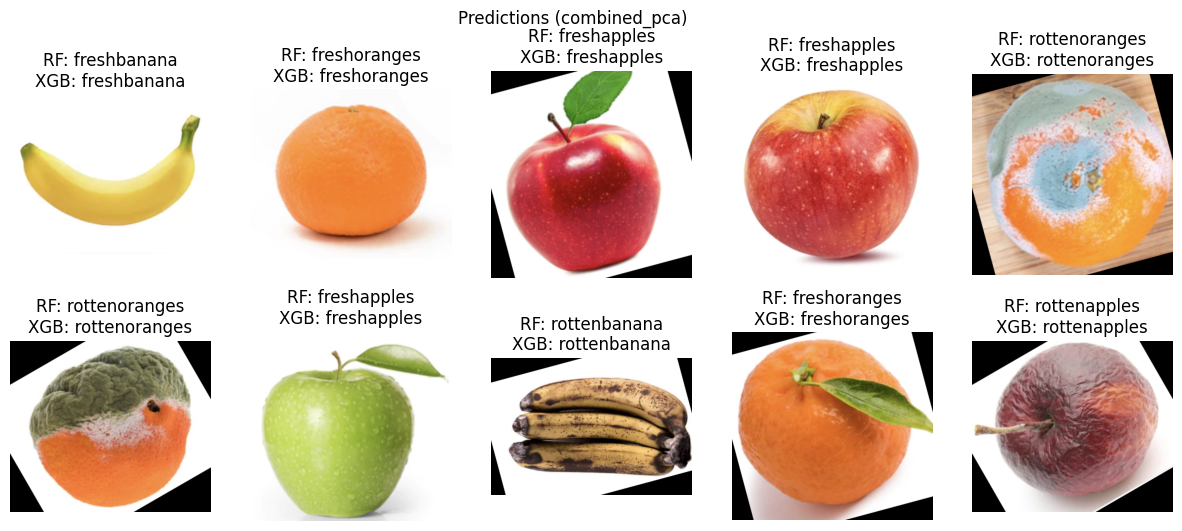


✅ ML training, evaluation, SHAP top 5 feature explanation, and prediction display complete!


In [4]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import os
import pandas as pd
import cv2
import random
import shap

# Define class labels
class_labels = ["freshapples", "freshbanana", "freshoranges", "rottenapples", "rottenbanana", "rottenoranges"]

# Models to use
models = {
    "RandomForest": RandomForestClassifier(n_estimators=100, random_state=42),
    "XGBoost": XGBClassifier(use_label_encoder=False, eval_metric='mlogloss')
}

# Store results for comparison
results = []

# Dictionary to store image predictions
image_predictions = {"fused_pca": [], "combined_pca": []}

# Train and evaluate models for both fused PCA and combined PCA
for pca_type in ["fused_pca", "combined_pca"]:
    print(f"\nTraining models on {pca_type} features...")
    
    # Load and prepare data
    X, y, image_paths = [], [], []
    for class_idx, class_name in enumerate(class_labels):
        feature_filename = f"efficient_{class_name}_{pca_type}_final.npy"
        image_folder = f"./dataset/test/{class_name}"  # Update with your actual image directory
       
        if not os.path.exists(feature_filename):
            print(f"Skipping {class_name}, file not found: {feature_filename}")
            continue
        
        features = np.load(feature_filename)
        image_files = sorted(os.listdir(image_folder))[:len(features)]  # Match features count
        
        X.append(features)
        y.extend([class_idx] * len(features))
        image_paths.extend([os.path.join(image_folder, img) for img in image_files])
    
    # Convert to numpy arrays
    X = np.vstack(X)
    y = np.array(y)
    
    # Split data
    X_train, X_test, y_train, y_test, image_paths_train, image_paths_test = train_test_split(
        X, y, image_paths, test_size=0.2, random_state=42
    )
    
    # Select 10 random images for prediction display
    sample_indices = random.sample(range(len(X_test)), 10)
    X_sample = X_test[sample_indices]
    y_sample = y_test[sample_indices]
    image_sample_paths = [image_paths_test[i] for i in sample_indices]
    
    # Train and evaluate each model
    for model_name, model in models.items():
        print(f"\nTraining {model_name} on {pca_type}...")
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
        
        # Evaluate performance
        acc = accuracy_score(y_test, y_pred)
        class_report = classification_report(y_test, y_pred, target_names=class_labels, output_dict=True)
        conf_matrix = confusion_matrix(y_test, y_pred)
        
        # SHAP Explainability (Top 5 Features)
        print(f"\nExplaining Top 5 features with SHAP for {model_name} on {pca_type}...")
        try:
            if model_name == "RandomForest":
                explainer = shap.TreeExplainer(model)
            elif model_name == "XGBoost":
                explainer = shap.Explainer(model)
            
            shap_values = explainer(X_test)
            feature_names = [f'PC{i+1}' for i in range(X.shape[1])]

            shap.summary_plot(
                shap_values,
                features=X_test,
                feature_names=feature_names,
                plot_type="bar",
                max_display=5  # Show Top 5 Features
            )
        except Exception as e:
            print(f"SHAP failed for {model_name} on {pca_type}: {e}")
        
        # Store results
        results.append({
            "Model": model_name,
            "PCA Type": pca_type,
            "Accuracy": acc,
            "Precision": {label: class_report[label]["precision"] for label in class_labels},
            "Recall": {label: class_report[label]["recall"] for label in class_labels},
            "F1-score": {label: class_report[label]["f1-score"] for label in class_labels},
            "Confusion Matrix": conf_matrix
        })
        
        # Print evaluation metrics
        print(f"Accuracy ({model_name} on {pca_type}): {acc:.4f}")
        print(classification_report(y_test, y_pred, target_names=class_labels))
        
        # Store predictions for sample images
        y_sample_pred = model.predict(X_sample)
        image_predictions[pca_type].append((model_name, y_sample_pred))

# Display images with predictions
for pca_type in ["fused_pca", "combined_pca"]:
    print(f"\nDisplaying predictions for {pca_type}...")
    plt.figure(figsize=(15, 6))
    for idx, img_path in enumerate(image_sample_paths):
        img = cv2.imread(img_path)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        
        rf_pred = class_labels[image_predictions[pca_type][0][1][idx]]  # RandomForest prediction
        xgb_pred = class_labels[image_predictions[pca_type][1][1][idx]]  # XGBoost prediction
        
        plt.subplot(2, 5, idx + 1)
        plt.imshow(img)
        plt.axis("off")
        plt.title(f"RF: {rf_pred}\nXGB: {xgb_pred}")
    plt.suptitle(f"Predictions ({pca_type})")
    plt.show()

print("\n✅ ML training, evaluation, SHAP top 5 feature explanation, and prediction display complete!")


In [5]:
import numpy as np
import os
import joblib
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.applications.efficientnet import preprocess_input
from tensorflow.keras.preprocessing import image
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
import pickle

# Define labels and custom image list
class_labels = ["freshapples", "freshbanana", "freshoranges", "rottenapples", "rottenbanana", "rottenoranges"]

custom_images = [
    "banana rotten.jpg", "download (1).jpeg", "download (4).jpeg", "download (5).jpeg",
    "download 10.jpeg", "download 20.jpeg", "fresh apple.jpeg", "fresh banana.jpeg",
    "fresh orange.jpeg", "image 1.jpg"
]

# Load EfficientNetB0 model
eff_model = EfficientNetB0(weights='imagenet', include_top=False, pooling='avg')

# Load trained classifiers (you must save them after training)
def load_model(filename):
    with open(filename, "rb") as f:
        return pickle.load(f)

models = {
    "RandomForest": load_model("rf_model_fused_pca.pkl"),
    "XGBoost": load_model("xgb_model_fused_pca.pkl")
}

# Predict on images using existing PCA models
for pca_type in ["fused_pca", "combined_pca"]:
    print(f"\n📦 Using {pca_type} features")

    # Load corresponding PCA model
    pca = joblib.load(f"{pca_type}_model.pkl")  # Example: fused_pca_model.pkl

    for img_name in custom_images:
        img_path = os.path.join("./dataset/", img_name)

        try:
            # Load and preprocess image
            img = image.load_img(img_path, target_size=(224, 224))
            img_array = image.img_to_array(img)
            img_array = np.expand_dims(img_array, axis=0)
            img_array = preprocess_input(img_array)

            # Feature extraction and PCA transform
            features = eff_model.predict(img_array)
            features_pca = pca.transform(features)

            print(f"\n📸 {img_name} predictions:")
            for model_name, model in models.items():
                pred = model.predict(features_pca)[0]
                print(f"{model_name} ({pca_type}): {class_labels[pred]}")

        except Exception as e:
            print(f"❌ Failed to process {img_name}: {e}")


KeyboardInterrupt: 


Training models on fused_pca features...

Training RandomForest on fused_pca...
Accuracy (RandomForest on fused_pca): 1.0000
               precision    recall  f1-score   support

  freshapples       1.00      1.00      1.00        23
  freshbanana       1.00      1.00      1.00        20
 freshoranges       1.00      1.00      1.00        19
 rottenapples       1.00      1.00      1.00        17
 rottenbanana       1.00      1.00      1.00        17
rottenoranges       1.00      1.00      1.00        24

     accuracy                           1.00       120
    macro avg       1.00      1.00      1.00       120
 weighted avg       1.00      1.00      1.00       120



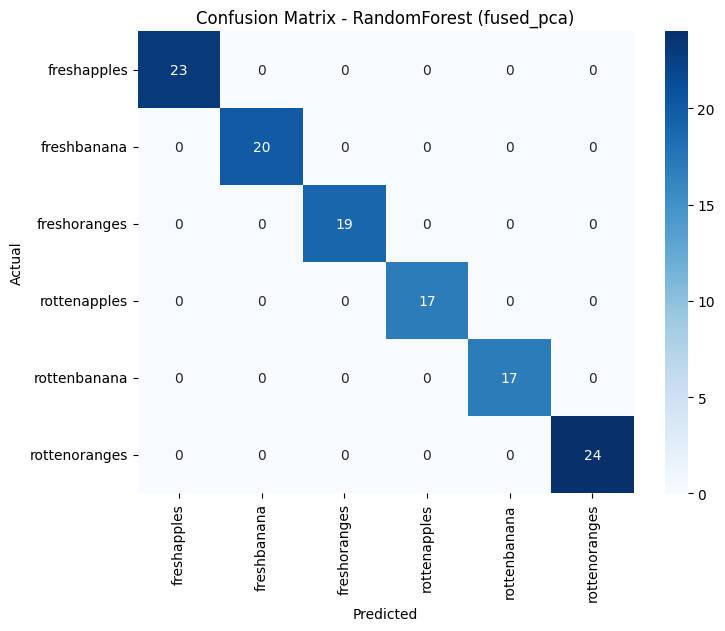


Training XGBoost on fused_pca...


c:\Users\Asus\Documents\FRUIT CLASSIFICATION PROJECT\venv\Lib\site-packages\xgboost\core.py:158: UserWarning: [13:13:56] WARNING: C:\buildkite-agent\builds\buildkite-windows-cpu-autoscaling-group-i-08cbc0333d8d4aae1-1\xgboost\xgboost-ci-windows\src\learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)


Accuracy (XGBoost on fused_pca): 0.9917
               precision    recall  f1-score   support

  freshapples       1.00      1.00      1.00        23
  freshbanana       0.95      1.00      0.98        20
 freshoranges       1.00      1.00      1.00        19
 rottenapples       1.00      1.00      1.00        17
 rottenbanana       1.00      1.00      1.00        17
rottenoranges       1.00      0.96      0.98        24

     accuracy                           0.99       120
    macro avg       0.99      0.99      0.99       120
 weighted avg       0.99      0.99      0.99       120



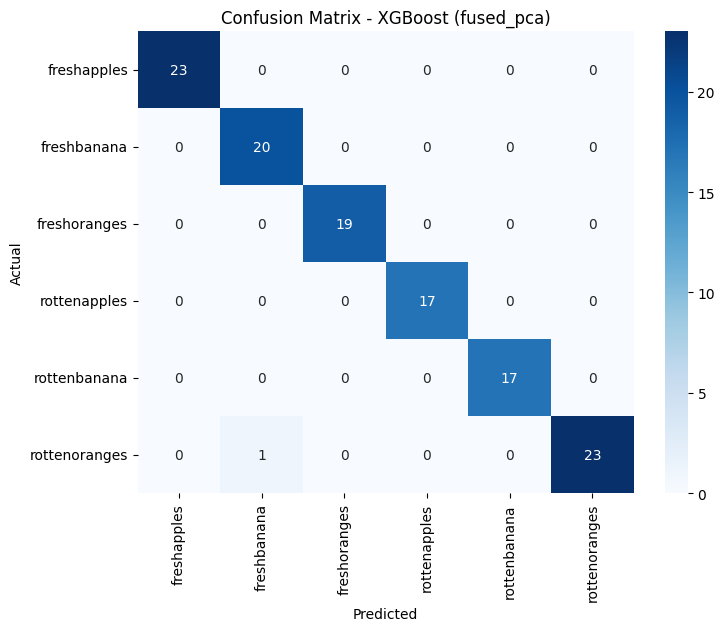


Training models on combined_pca features...

Training RandomForest on combined_pca...
Accuracy (RandomForest on combined_pca): 0.9083
               precision    recall  f1-score   support

  freshapples       0.96      1.00      0.98        23
  freshbanana       1.00      1.00      1.00        20
 freshoranges       0.84      0.84      0.84        19
 rottenapples       0.94      1.00      0.97        17
 rottenbanana       0.83      0.88      0.86        17
rottenoranges       0.86      0.75      0.80        24

     accuracy                           0.91       120
    macro avg       0.91      0.91      0.91       120
 weighted avg       0.91      0.91      0.91       120



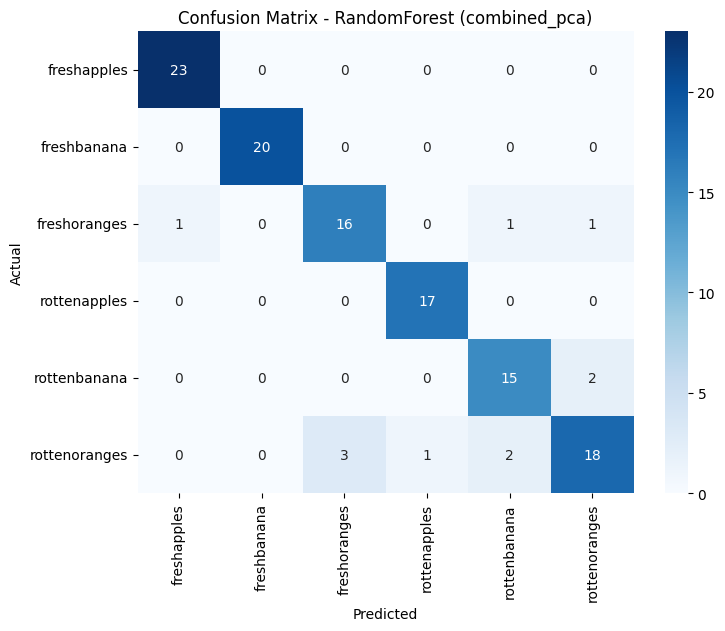


Training XGBoost on combined_pca...


c:\Users\Asus\Documents\FRUIT CLASSIFICATION PROJECT\venv\Lib\site-packages\xgboost\core.py:158: UserWarning: [13:13:57] WARNING: C:\buildkite-agent\builds\buildkite-windows-cpu-autoscaling-group-i-08cbc0333d8d4aae1-1\xgboost\xgboost-ci-windows\src\learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)


Accuracy (XGBoost on combined_pca): 0.9833
               precision    recall  f1-score   support

  freshapples       1.00      1.00      1.00        23
  freshbanana       1.00      0.90      0.95        20
 freshoranges       1.00      1.00      1.00        19
 rottenapples       0.89      1.00      0.94        17
 rottenbanana       1.00      1.00      1.00        17
rottenoranges       1.00      1.00      1.00        24

     accuracy                           0.98       120
    macro avg       0.98      0.98      0.98       120
 weighted avg       0.99      0.98      0.98       120



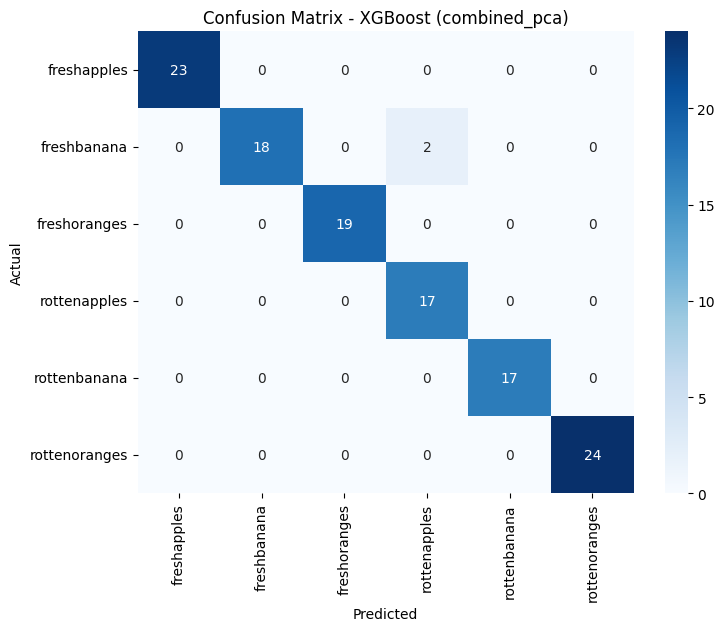


ML model training and evaluation complete for both PCA types!
RandomForest (fused_pca) - Accuracy: 1.0000
XGBoost (fused_pca) - Accuracy: 0.9917
RandomForest (combined_pca) - Accuracy: 0.9083
XGBoost (combined_pca) - Accuracy: 0.9833


In [2]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import os

# Define class labels
class_labels = ["freshapples", "freshbanana", "freshoranges", "rottenapples", "rottenbanana", "rottenoranges"]

# Models to use
models = {
    "RandomForest": RandomForestClassifier(n_estimators=100, random_state=42),
    "XGBoost": XGBClassifier(use_label_encoder=False, eval_metric='mlogloss')
}

# Store results for comparison
results = []

# Train and evaluate models for both fused PCA and combined PCA
for pca_type in ["fused_pca", "combined_pca"]:
    print(f"\nTraining models on {pca_type} features...")
    
    # Load and prepare data
    X, y = [], []
    for class_idx, class_name in enumerate(class_labels):
        feature_filename = f"efficient_{class_name}_{pca_type}_final.npy"
        if not os.path.exists(feature_filename):
            print(f"Skipping {class_name}, file not found: {feature_filename}")
            continue
        
        features = np.load(feature_filename)
        X.append(features)
        y.extend([class_idx] * len(features))
    
    # Convert to numpy arrays
    X = np.vstack(X)
    y = np.array(y)
    
    # Split data
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    
    # Train and evaluate each model
    for model_name, model in models.items():
        print(f"\nTraining {model_name} on {pca_type}...")
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
        
        # Evaluate performance
        acc = accuracy_score(y_test, y_pred)
        class_report = classification_report(y_test, y_pred, target_names=class_labels, output_dict=True)
        conf_matrix = confusion_matrix(y_test, y_pred)
        
        # Store results
        results.append({
            "Model": model_name,
            "PCA Type": pca_type,
            "Accuracy": acc,
            "Precision": {label: class_report[label]["precision"] for label in class_labels},
            "Recall": {label: class_report[label]["recall"] for label in class_labels},
            "F1-score": {label: class_report[label]["f1-score"] for label in class_labels},
            "Confusion Matrix": conf_matrix
        })
        
        # Print evaluation metrics
        print(f"Accuracy ({model_name} on {pca_type}): {acc:.4f}")
        print(classification_report(y_test, y_pred, target_names=class_labels))
        
        # Plot confusion matrix
        plt.figure(figsize=(8, 6))
        sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues", xticklabels=class_labels, yticklabels=class_labels)
        plt.xlabel("Predicted")
        plt.ylabel("Actual")
        plt.title(f"Confusion Matrix - {model_name} ({pca_type})")
        plt.show()

print("\nML model training and evaluation complete for both PCA types!")

# Display model accuracy comparison
for result in results:
    print(f"{result['Model']} ({result['PCA Type']}) - Accuracy: {result['Accuracy']:.4f}")



Training models on fused_pca features...

Training RandomForest on fused_pca...
Accuracy (RandomForest on fused_pca): 1.0000
               precision    recall  f1-score   support

  freshapples       1.00      1.00      1.00        23
  freshbanana       1.00      1.00      1.00        20
 freshoranges       1.00      1.00      1.00        19
 rottenapples       1.00      1.00      1.00        17
 rottenbanana       1.00      1.00      1.00        17
rottenoranges       1.00      1.00      1.00        24

     accuracy                           1.00       120
    macro avg       1.00      1.00      1.00       120
 weighted avg       1.00      1.00      1.00       120



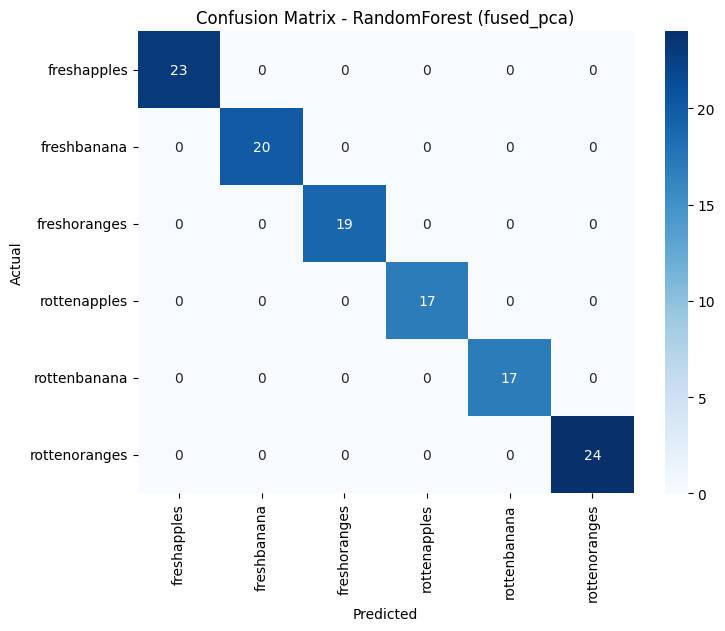

Top 5 features for RandomForest (fused_pca): [[3 0 4 5 2 1]
 [2 1 4 0 5 3]
 [0 4 1 5 2 3]
 [2 1 5 3 4 0]
 [1 3 4 0 5 2]]


C:\Users\Asus\AppData\Local\Temp\ipykernel_21036\2763069693.py:94: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values, X_test, feature_names=[f"Feature {i}" for i in range(X.shape[1])])
c:\Users\Asus\Documents\FRUIT CLASSIFICATION PROJECT\venv\Lib\site-packages\shap\plots\_beeswarm.py:726: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  summary_legacy(
c:\Users\Asus\Documents\FRUIT CLASSIFICATION PROJECT\venv\Lib\site-packages\shap\plots\_beeswarm.py:746: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` e

<Figure size 640x480 with 0 Axes>

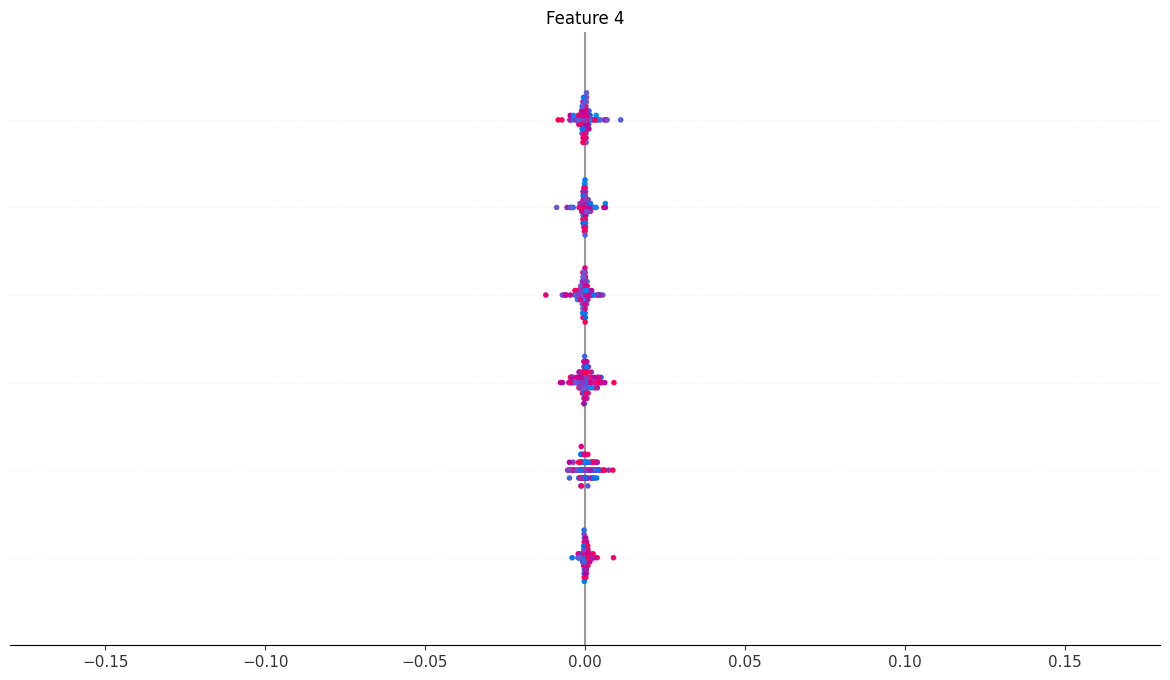

ValueError: Per-column arrays must each be 1-dimensional

<Figure size 800x500 with 0 Axes>

In [9]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import shap
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import os
import pandas as pd

# Define class labels
class_labels = ["freshapples", "freshbanana", "freshoranges", "rottenapples", "rottenbanana", "rottenoranges"]

# Models to use
models = {
    "RandomForest": RandomForestClassifier(n_estimators=100, random_state=42),
    "XGBoost": XGBClassifier(use_label_encoder=False, eval_metric='mlogloss')
}

# Store results for comparison
results = []

# Train and evaluate models for both fused PCA and combined PCA
for pca_type in ["fused_pca", "combined_pca"]:
    print(f"\nTraining models on {pca_type} features...")

    # Load and prepare data
    X, y = [], []
    for class_idx, class_name in enumerate(class_labels):
        feature_filename = f"efficient_{class_name}_{pca_type}_final.npy"
        if not os.path.exists(feature_filename):
            print(f"Skipping {class_name}, file not found: {feature_filename}")
            continue
        
        features = np.load(feature_filename)
        X.append(features)
        y.extend([class_idx] * len(features))
    
    # Convert to numpy arrays
    X = np.vstack(X)
    y = np.array(y)
    
    # Split data
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    
    # Train and evaluate each model
    for model_name, model in models.items():
        print(f"\nTraining {model_name} on {pca_type}...")
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
        
        # Evaluate performance
        acc = accuracy_score(y_test, y_pred)
        class_report = classification_report(y_test, y_pred, target_names=class_labels, output_dict=True)
        conf_matrix = confusion_matrix(y_test, y_pred)
        
        # Store results
        results.append({
            "Model": model_name,
            "PCA Type": pca_type,
            "Accuracy": acc,
            "Precision": {label: class_report[label]["precision"] for label in class_labels},
            "Recall": {label: class_report[label]["recall"] for label in class_labels},
            "F1-score": {label: class_report[label]["f1-score"] for label in class_labels},
            "Confusion Matrix": conf_matrix
        })
        
        # Print evaluation metrics
        print(f"Accuracy ({model_name} on {pca_type}): {acc:.4f}")
        print(classification_report(y_test, y_pred, target_names=class_labels))
        
        # Plot confusion matrix
        plt.figure(figsize=(8, 6))
        sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues", xticklabels=class_labels, yticklabels=class_labels)
        plt.xlabel("Predicted")
        plt.ylabel("Actual")
        plt.title(f"Confusion Matrix - {model_name} ({pca_type})")
        plt.show()

        # Compute SHAP values for feature importance
        explainer = shap.TreeExplainer(model) if model_name == "XGBoost" else shap.Explainer(model)
        shap_values = explainer.shap_values(X_test)

        # Get mean absolute SHAP values for feature importance
        feature_importance = np.abs(shap_values).mean(axis=0)

        # Get top 5 most important features
        top_5_features = np.argsort(feature_importance)[-5:][::-1]

        print(f"Top 5 features for {model_name} ({pca_type}): {top_5_features}")

        # Plot SHAP summary plot
        shap.summary_plot(shap_values, X_test, feature_names=[f"Feature {i}" for i in range(X.shape[1])])

        # Plot bar chart for feature importance
        plt.figure(figsize=(8, 5))
        sns.barplot(x=top_5_features, y=feature_importance[top_5_features], palette="Blues_r")
        plt.xlabel("Feature Index")
        plt.ylabel("SHAP Value Importance")
        plt.title(f"Top 5 Important Features - {model_name} ({pca_type})")
        plt.show()

# Convert results to DataFrame for plotting
df_results = []
for result in results:
    for label in class_labels:
        df_results.append({
            "Model": result["Model"],
            "PCA Type": result["PCA Type"],
            "Class": label,
            "Precision": result["Precision"][label],
            "Recall": result["Recall"][label],
            "F1-score": result["F1-score"][label]
        })

df_results = pd.DataFrame(df_results)

# Plot Precision, Recall, and F1-score Comparison
metrics = ["Precision", "Recall", "F1-score"]
for metric in metrics:
    plt.figure(figsize=(10, 6))
    sns.barplot(x="Class", y=metric, hue="Model", data=df_results)
    plt.title(f"{metric} Comparison Across Classes")
    plt.ylabel(metric)
    plt.xlabel("Class")
    plt.xticks(rotation=45)
    plt.legend(title="Model")
    plt.show()

print("\nML model training, evaluation, and graphical representation complete for both PCA types!")

# Display model accuracy comparison
for result in results:
    print(f"{result['Model']} ({result['PCA Type']}) - Accuracy: {result['Accuracy']:.4f}")



Training models on fused_pca features...

Training RandomForest on fused_pca...
Accuracy (RandomForest on fused_pca): 1.0000
               precision    recall  f1-score   support

  freshapples       1.00      1.00      1.00        23
  freshbanana       1.00      1.00      1.00        20
 freshoranges       1.00      1.00      1.00        19
 rottenapples       1.00      1.00      1.00        17
 rottenbanana       1.00      1.00      1.00        17
rottenoranges       1.00      1.00      1.00        24

     accuracy                           1.00       120
    macro avg       1.00      1.00      1.00       120
 weighted avg       1.00      1.00      1.00       120



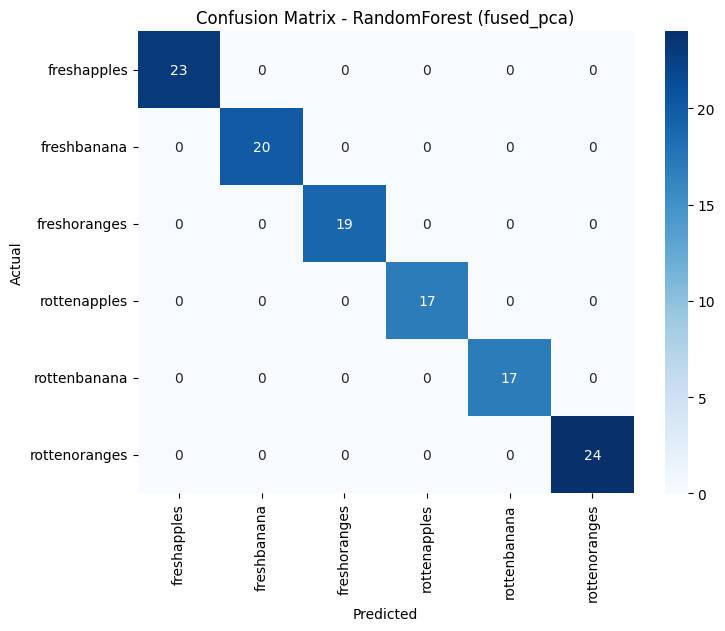


Training XGBoost on fused_pca...


c:\Users\Asus\Documents\FRUIT CLASSIFICATION PROJECT\venv\Lib\site-packages\xgboost\core.py:158: UserWarning: [15:27:51] WARNING: C:\buildkite-agent\builds\buildkite-windows-cpu-autoscaling-group-i-08cbc0333d8d4aae1-1\xgboost\xgboost-ci-windows\src\learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)


Accuracy (XGBoost on fused_pca): 0.9917
               precision    recall  f1-score   support

  freshapples       1.00      1.00      1.00        23
  freshbanana       0.95      1.00      0.98        20
 freshoranges       1.00      1.00      1.00        19
 rottenapples       1.00      1.00      1.00        17
 rottenbanana       1.00      1.00      1.00        17
rottenoranges       1.00      0.96      0.98        24

     accuracy                           0.99       120
    macro avg       0.99      0.99      0.99       120
 weighted avg       0.99      0.99      0.99       120



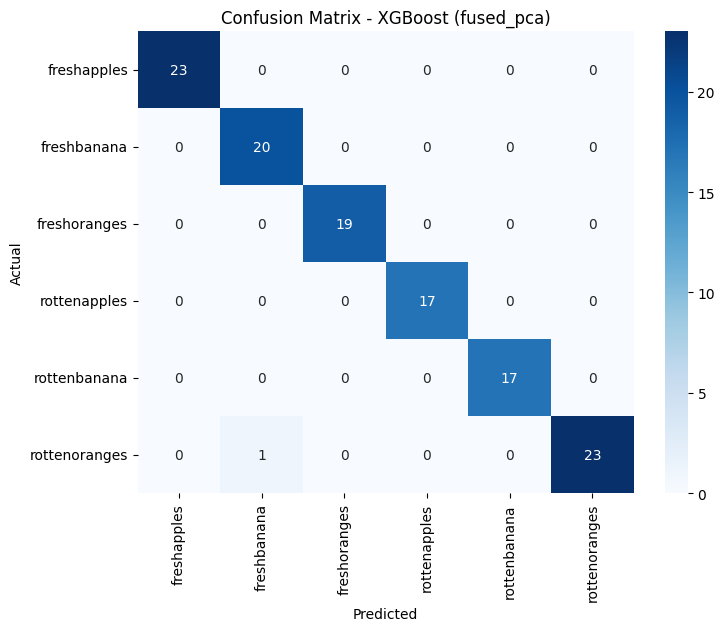


Training models on combined_pca features...

Training RandomForest on combined_pca...
Accuracy (RandomForest on combined_pca): 0.9083
               precision    recall  f1-score   support

  freshapples       0.96      1.00      0.98        23
  freshbanana       1.00      1.00      1.00        20
 freshoranges       0.84      0.84      0.84        19
 rottenapples       0.94      1.00      0.97        17
 rottenbanana       0.83      0.88      0.86        17
rottenoranges       0.86      0.75      0.80        24

     accuracy                           0.91       120
    macro avg       0.91      0.91      0.91       120
 weighted avg       0.91      0.91      0.91       120



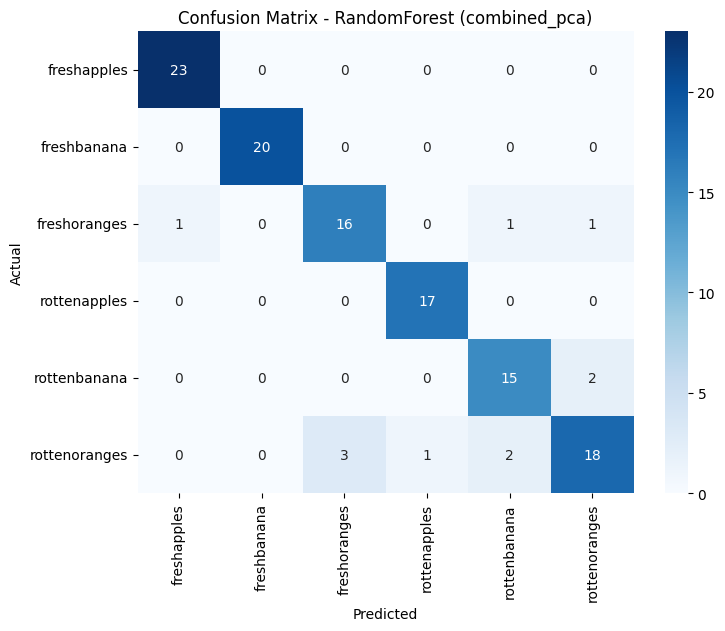


Training XGBoost on combined_pca...


c:\Users\Asus\Documents\FRUIT CLASSIFICATION PROJECT\venv\Lib\site-packages\xgboost\core.py:158: UserWarning: [15:27:53] WARNING: C:\buildkite-agent\builds\buildkite-windows-cpu-autoscaling-group-i-08cbc0333d8d4aae1-1\xgboost\xgboost-ci-windows\src\learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)


Accuracy (XGBoost on combined_pca): 0.9833
               precision    recall  f1-score   support

  freshapples       1.00      1.00      1.00        23
  freshbanana       1.00      0.90      0.95        20
 freshoranges       1.00      1.00      1.00        19
 rottenapples       0.89      1.00      0.94        17
 rottenbanana       1.00      1.00      1.00        17
rottenoranges       1.00      1.00      1.00        24

     accuracy                           0.98       120
    macro avg       0.98      0.98      0.98       120
 weighted avg       0.99      0.98      0.98       120



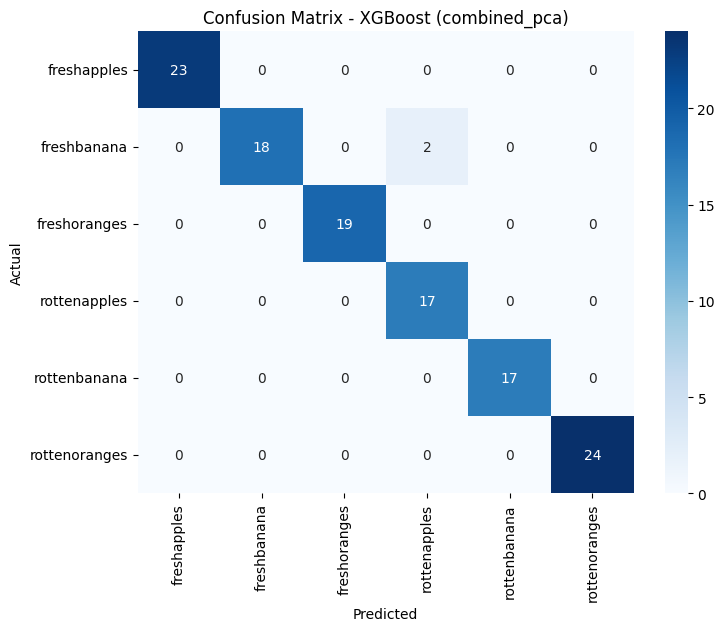

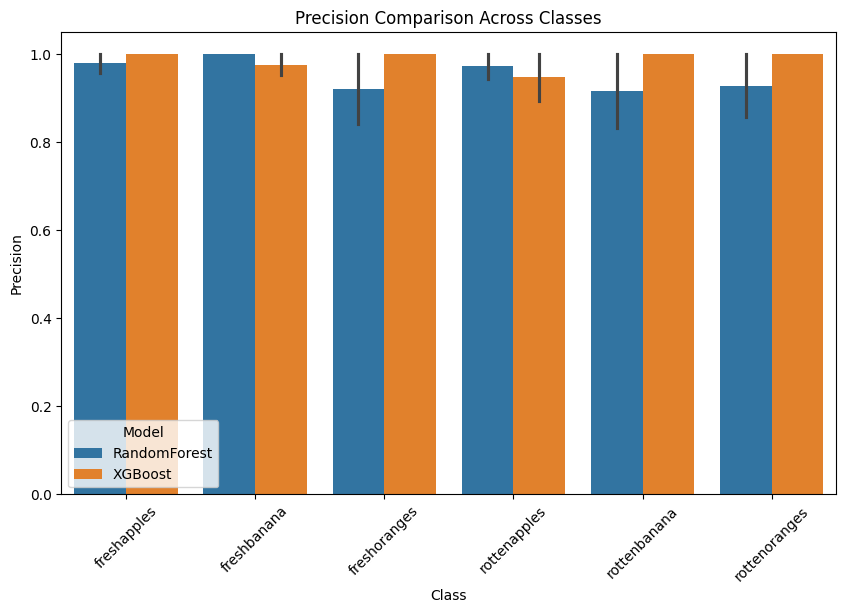

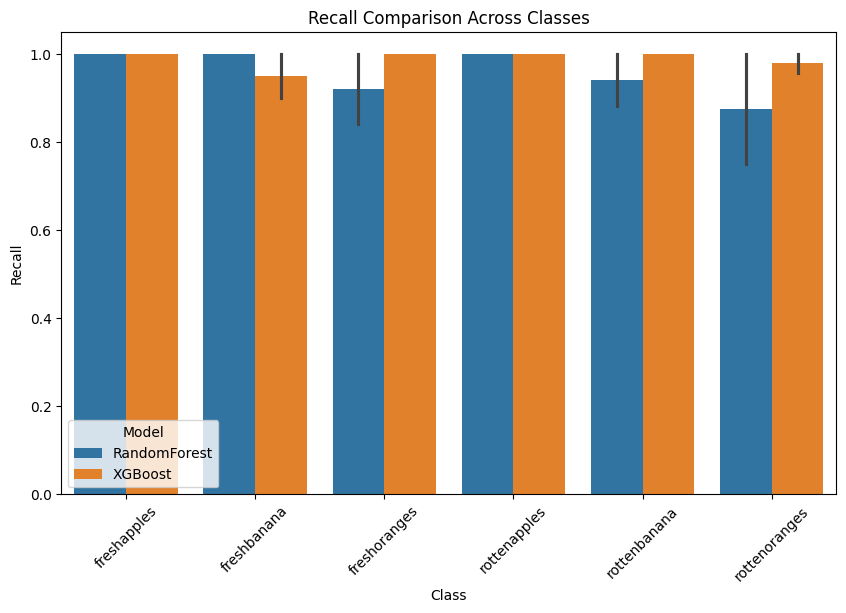

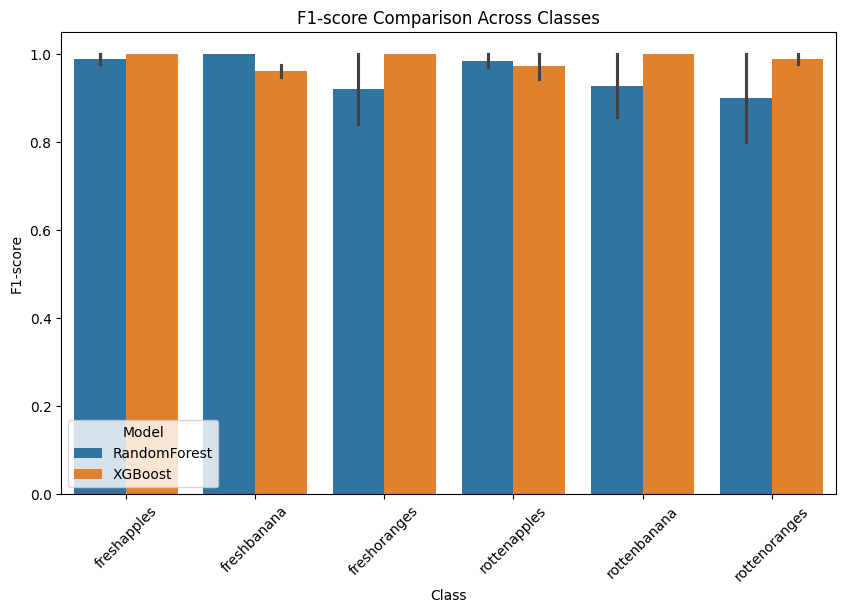


ML model training, evaluation, and graphical representation complete for both PCA types!
RandomForest (fused_pca) - Accuracy: 1.0000
XGBoost (fused_pca) - Accuracy: 0.9917
RandomForest (combined_pca) - Accuracy: 0.9083
XGBoost (combined_pca) - Accuracy: 0.9833


In [10]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import os
import pandas as pd

# Define class labels
class_labels = ["freshapples", "freshbanana", "freshoranges", "rottenapples", "rottenbanana", "rottenoranges"]

# Models to use
models = {
    "RandomForest": RandomForestClassifier(n_estimators=100, random_state=42),
    "XGBoost": XGBClassifier(use_label_encoder=False, eval_metric='mlogloss')
}

# Store results for comparison
results = []

# Train and evaluate models for both fused PCA and combined PCA
for pca_type in ["fused_pca", "combined_pca"]:
    print(f"\nTraining models on {pca_type} features...")
    
    # Load and prepare data
    X, y = [], []
    for class_idx, class_name in enumerate(class_labels):
        feature_filename = f"efficient_{class_name}_{pca_type}_final.npy"
        if not os.path.exists(feature_filename):
            print(f"Skipping {class_name}, file not found: {feature_filename}")
            continue
        
        features = np.load(feature_filename)
        X.append(features)
        y.extend([class_idx] * len(features))
    
    # Convert to numpy arrays
    X = np.vstack(X)
    y = np.array(y)
    
    # Split data
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    
    # Train and evaluate each model
    for model_name, model in models.items():
        print(f"\nTraining {model_name} on {pca_type}...")
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
        
        # Evaluate performance
        acc = accuracy_score(y_test, y_pred)
        class_report = classification_report(y_test, y_pred, target_names=class_labels, output_dict=True)
        conf_matrix = confusion_matrix(y_test, y_pred)
        
        # Store results
        results.append({
            "Model": model_name,
            "PCA Type": pca_type,
            "Accuracy": acc,
            "Precision": {label: class_report[label]["precision"] for label in class_labels},
            "Recall": {label: class_report[label]["recall"] for label in class_labels},
            "F1-score": {label: class_report[label]["f1-score"] for label in class_labels},
            "Confusion Matrix": conf_matrix
        })
        
        # Print evaluation metrics
        print(f"Accuracy ({model_name} on {pca_type}): {acc:.4f}")
        print(classification_report(y_test, y_pred, target_names=class_labels))
        
        # Plot confusion matrix
        plt.figure(figsize=(8, 6))
        sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues", xticklabels=class_labels, yticklabels=class_labels)
        plt.xlabel("Predicted")
        plt.ylabel("Actual")
        plt.title(f"Confusion Matrix - {model_name} ({pca_type})")
        plt.show()

# Convert results to DataFrame for plotting
df_results = []
for result in results:
    for label in class_labels:
        df_results.append({
            "Model": result["Model"],
            "PCA Type": result["PCA Type"],
            "Class": label,
            "Precision": result["Precision"][label],
            "Recall": result["Recall"][label],
            "F1-score": result["F1-score"][label]
        })

df_results = pd.DataFrame(df_results)

# Plot Precision, Recall, and F1-score Comparison
metrics = ["Precision", "Recall", "F1-score"]
for metric in metrics:
    plt.figure(figsize=(10, 6))
    sns.barplot(x="Class", y=metric, hue="Model", data=df_results)
    plt.title(f"{metric} Comparison Across Classes")
    plt.ylabel(metric)
    plt.xlabel("Class")
    plt.xticks(rotation=45)
    plt.legend(title="Model")
    plt.show()

print("\nML model training, evaluation, and graphical representation complete for both PCA types!")

# Display model accuracy comparison
for result in results:
    print(f"{result['Model']} ({result['PCA Type']}) - Accuracy: {result['Accuracy']:.4f}")

In [12]:
import shap
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Assuming 'model' is your trained model and 'X_train' is your dataset
explainer = shap.Explainer(model, X_train)
shap_values = explainer(X_train)

# Compute mean absolute SHAP values for each feature
mean_shap_values = np.abs(shap_values.values).mean(axis=0)

# Select top 5 important features
feature_indices = np.argsort(mean_shap_values)[-5:]

# Ensure SHAP values are 1D for plotting
mean_shap_values = np.array(mean_shap_values).flatten()

# Plot feature importance
plt.figure(figsize=(8, 5))
sns.barplot(x=mean_shap_values[feature_indices], 
            y=[f"Feature {i}" for i in feature_indices], 
            palette="viridis")

plt.xlabel("Mean SHAP Value")
plt.ylabel("Feature Index")
plt.title("Feature Importance using SHAP Values")
plt.show()


 96%|=================== | 2768/2880 [00:26<00:01]       

ValueError: Per-column arrays must each be 1-dimensional

<Figure size 800x500 with 0 Axes>

In [11]:
import shap
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.model_selection import train_test_split
import os

# Define class labels
class_labels = ["freshapples", "freshbanana", "freshoranges", "rottenapples", "rottenbanana", "rottenoranges"]

# Models to use
models = {
    "RandomForest": RandomForestClassifier(n_estimators=100, random_state=42),
    "XGBoost": XGBClassifier(use_label_encoder=False, eval_metric='mlogloss')
}

# Train and compute SHAP values for both PCA types
for pca_type in ["fused_pca", "combined_pca"]:
    print(f"\nProcessing SHAP for {pca_type}...")
    
    # Load and prepare data
    X, y = [], []
    for class_idx, class_name in enumerate(class_labels):
        feature_filename = f"efficient_{class_name}_{pca_type}_final.npy"
        if not os.path.exists(feature_filename):
            continue
        features = np.load(feature_filename)
        X.append(features)
        y.extend([class_idx] * len(features))
    
    if len(X) == 0:
        print(f"Skipping {pca_type} as no data found.")
        continue
    
    X = np.vstack(X)
    y = np.array(y)
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    
    for model_name, model in models.items():
        print(f"\nTraining {model_name} on {pca_type}...")
        model.fit(X_train, y_train)
        
        # Compute SHAP values
        explainer = shap.TreeExplainer(model) if model_name == "XGBoost" else shap.Explainer(model)
        shap_values = explainer.shap_values(X_train)
        
        # Get mean SHAP values for feature importance
        mean_shap_values = np.abs(shap_values).mean(axis=0)
        feature_indices = np.argsort(mean_shap_values)[-5:][::-1]  # Top 5 features
        
        # Plot feature importance
        plt.figure(figsize=(8, 5))
        sns.barplot(x=mean_shap_values[feature_indices], y=[f"Feature {i}" for i in feature_indices], palette="viridis")
        plt.xlabel("Mean SHAP Value")
        plt.ylabel("Feature Index")
        plt.title(f"Top 5 SHAP Features - {model_name} ({pca_type})")
        plt.show()



Processing SHAP for fused_pca...

Training RandomForest on fused_pca...


ValueError: Per-column arrays must each be 1-dimensional

<Figure size 800x500 with 0 Axes>


Training models on fused_pca features...

Training RandomForest on fused_pca...


 98%|===================| 2832/2880 [00:27<00:00]        

Accuracy (RandomForest on fused_pca): 1.0000
               precision    recall  f1-score   support

  freshapples       1.00      1.00      1.00        23
  freshbanana       1.00      1.00      1.00        20
 freshoranges       1.00      1.00      1.00        19
 rottenapples       1.00      1.00      1.00        17
 rottenbanana       1.00      1.00      1.00        17
rottenoranges       1.00      1.00      1.00        24

     accuracy                           1.00       120
    macro avg       1.00      1.00      1.00       120
 weighted avg       1.00      1.00      1.00       120



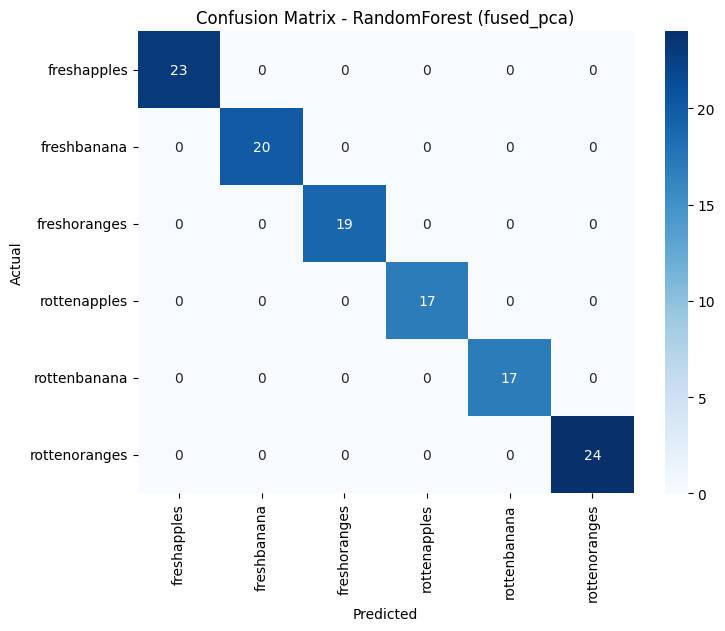


Training XGBoost on fused_pca...


c:\Users\Asus\Documents\FRUIT CLASSIFICATION PROJECT\venv\Lib\site-packages\xgboost\core.py:158: UserWarning: [15:32:58] WARNING: C:\buildkite-agent\builds\buildkite-windows-cpu-autoscaling-group-i-08cbc0333d8d4aae1-1\xgboost\xgboost-ci-windows\src\learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)


Accuracy (XGBoost on fused_pca): 0.9917
               precision    recall  f1-score   support

  freshapples       1.00      1.00      1.00        23
  freshbanana       0.95      1.00      0.98        20
 freshoranges       1.00      1.00      1.00        19
 rottenapples       1.00      1.00      1.00        17
 rottenbanana       1.00      1.00      1.00        17
rottenoranges       1.00      0.96      0.98        24

     accuracy                           0.99       120
    macro avg       0.99      0.99      0.99       120
 weighted avg       0.99      0.99      0.99       120



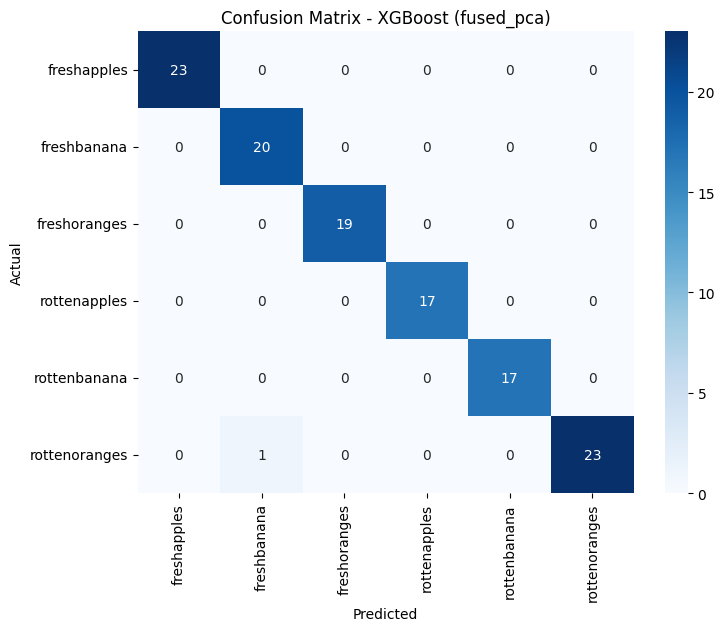


Training models on combined_pca features...

Training RandomForest on combined_pca...


 99%|===================| 2863/2880 [00:29<00:00]        

Accuracy (RandomForest on combined_pca): 0.9083
               precision    recall  f1-score   support

  freshapples       0.96      1.00      0.98        23
  freshbanana       1.00      1.00      1.00        20
 freshoranges       0.84      0.84      0.84        19
 rottenapples       0.94      1.00      0.97        17
 rottenbanana       0.83      0.88      0.86        17
rottenoranges       0.86      0.75      0.80        24

     accuracy                           0.91       120
    macro avg       0.91      0.91      0.91       120
 weighted avg       0.91      0.91      0.91       120



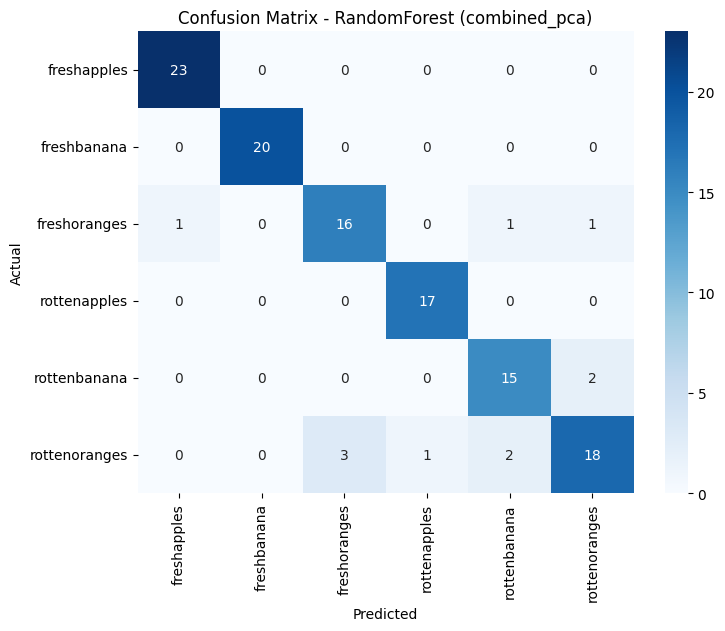


Training XGBoost on combined_pca...


c:\Users\Asus\Documents\FRUIT CLASSIFICATION PROJECT\venv\Lib\site-packages\xgboost\core.py:158: UserWarning: [15:33:32] WARNING: C:\buildkite-agent\builds\buildkite-windows-cpu-autoscaling-group-i-08cbc0333d8d4aae1-1\xgboost\xgboost-ci-windows\src\learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)


Accuracy (XGBoost on combined_pca): 0.9833
               precision    recall  f1-score   support

  freshapples       1.00      1.00      1.00        23
  freshbanana       1.00      0.90      0.95        20
 freshoranges       1.00      1.00      1.00        19
 rottenapples       0.89      1.00      0.94        17
 rottenbanana       1.00      1.00      1.00        17
rottenoranges       1.00      1.00      1.00        24

     accuracy                           0.98       120
    macro avg       0.98      0.98      0.98       120
 weighted avg       0.99      0.98      0.98       120



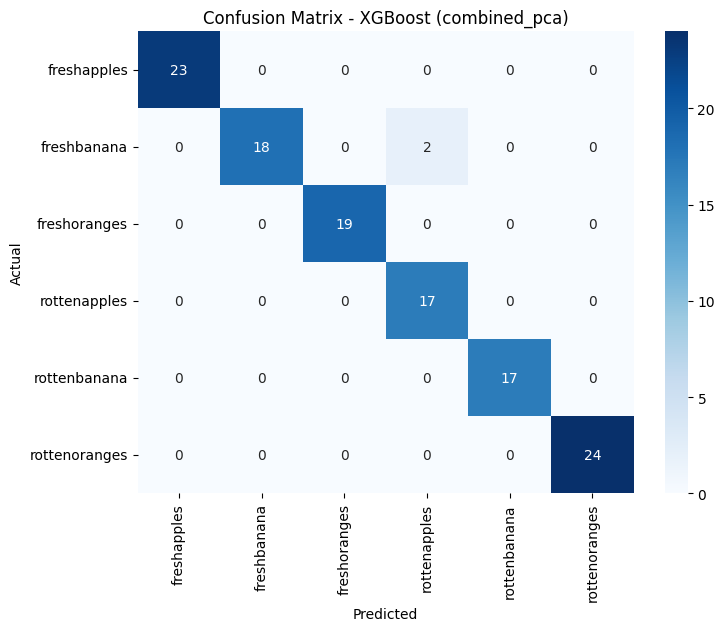

ValueError: Per-column arrays must each be 1-dimensional

<Figure size 800x500 with 0 Axes>

In [13]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import shap
import os
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Define class labels
class_labels = ["freshapples", "freshbanana", "freshoranges", "rottenapples", "rottenbanana", "rottenoranges"]

# Models to use
models = {
    "RandomForest": RandomForestClassifier(n_estimators=100, random_state=42),
    "XGBoost": XGBClassifier(use_label_encoder=False, eval_metric='mlogloss')
}

# Store results for comparison
results = []
shap_values_dict = {}

# Train and evaluate models for both fused PCA and combined PCA
for pca_type in ["fused_pca", "combined_pca"]:
    print(f"\nTraining models on {pca_type} features...")
    
    # Load and prepare data
    X, y = [], []
    for class_idx, class_name in enumerate(class_labels):
        feature_filename = f"efficient_{class_name}_{pca_type}_final.npy"
        if not os.path.exists(feature_filename):
            print(f"Skipping {class_name}, file not found: {feature_filename}")
            continue
        
        features = np.load(feature_filename)
        X.append(features)
        y.extend([class_idx] * len(features))
    
    # Convert to numpy arrays
    X = np.vstack(X)
    y = np.array(y)
    
    # Split data
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    
    # Train and evaluate each model
    for model_name, model in models.items():
        print(f"\nTraining {model_name} on {pca_type}...")
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
        
        # Evaluate performance
        acc = accuracy_score(y_test, y_pred)
        class_report = classification_report(y_test, y_pred, target_names=class_labels, output_dict=True)
        conf_matrix = confusion_matrix(y_test, y_pred)
        
        # Store results
        results.append({
            "Model": model_name,
            "PCA Type": pca_type,
            "Accuracy": acc,
            "Precision": {label: class_report[label]["precision"] for label in class_labels},
            "Recall": {label: class_report[label]["recall"] for label in class_labels},
            "F1-score": {label: class_report[label]["f1-score"] for label in class_labels},
            "Confusion Matrix": conf_matrix
        })
        
        # SHAP Analysis
        explainer = shap.Explainer(model, X_train)
        shap_values = explainer(X_train)
        mean_abs_shap_values = np.abs(shap_values.values).mean(axis=0)
        
        # Store SHAP values for plotting
        shap_values_dict[(model_name, pca_type)] = mean_abs_shap_values
        
        # Print evaluation metrics
        print(f"Accuracy ({model_name} on {pca_type}): {acc:.4f}")
        print(classification_report(y_test, y_pred, target_names=class_labels))
        
        # Plot confusion matrix
        plt.figure(figsize=(8, 6))
        sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues", xticklabels=class_labels, yticklabels=class_labels)
        plt.xlabel("Predicted")
        plt.ylabel("Actual")
        plt.title(f"Confusion Matrix - {model_name} ({pca_type})")
        plt.show()

# SHAP Feature Importance Visualization
for (model_name, pca_type), mean_abs_shap_values in shap_values_dict.items():
    top_5_features = np.argsort(mean_abs_shap_values)[-5:][::-1]
    
    plt.figure(figsize=(8, 5))
    sns.barplot(
        x=mean_abs_shap_values[top_5_features],
        y=[f"Feature {i}" for i in top_5_features],
        palette="viridis"
    )
    plt.xlabel("Mean SHAP Value")
    plt.ylabel("Feature Index")
    plt.title(f"Top 5 SHAP Features - {model_name} ({pca_type})")
    plt.show()

# Convert results to DataFrame for plotting
df_results = []
for result in results:
    for label in class_labels:
        df_results.append({
            "Model": result["Model"],
            "PCA Type": result["PCA Type"],
            "Class": label,
            "Precision": result["Precision"][label],
            "Recall": result["Recall"][label],
            "F1-score": result["F1-score"][label]
        })

df_results = pd.DataFrame(df_results)

# Plot Precision, Recall, and F1-score Comparison
metrics = ["Precision", "Recall", "F1-score"]
for metric in metrics:
    plt.figure(figsize=(10, 6))
    sns.barplot(x="Class", y=metric, hue="Model", data=df_results)
    plt.title(f"{metric} Comparison Across Classes")
    plt.ylabel(metric)
    plt.xlabel("Class")
    plt.xticks(rotation=45)
    plt.legend(title="Model")
    plt.show()

print("\nML model training, evaluation, SHAP analysis, and graphical representation complete for both PCA types!")

# Display model accuracy comparison
for result in results:
    print(f"{result['Model']} ({result['PCA Type']}) - Accuracy: {result['Accuracy']:.4f}")

C:\Users\Asus\AppData\Local\Temp\ipykernel_21036\258452099.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


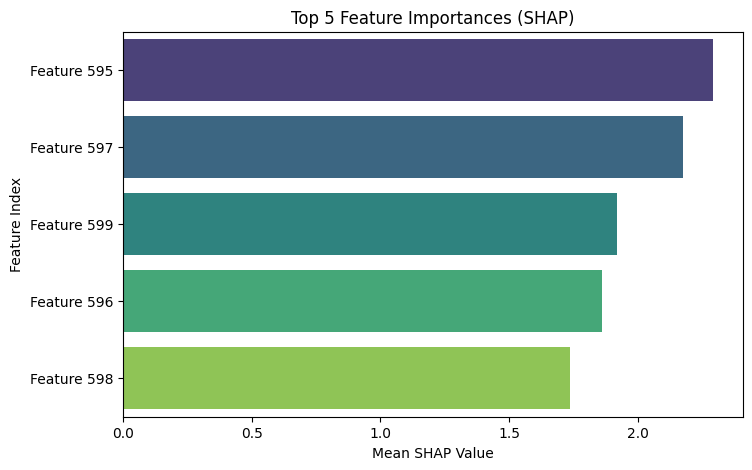

In [14]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Ensure SHAP values are in the correct shape
mean_abs_shap_values = np.abs(shap_values.values).mean(axis=0).flatten()  # Flatten ensures 1D

# Get top 5 features
top_5_features = np.argsort(mean_abs_shap_values)[-5:][::-1]

plt.figure(figsize=(8, 5))
sns.barplot(
    x=mean_abs_shap_values[top_5_features],  # Now guaranteed to be 1D
    y=[f"Feature {i}" for i in top_5_features],
    palette="viridis"
)

plt.xlabel("Mean SHAP Value")
plt.ylabel("Feature Index")
plt.title("Top 5 Feature Importances (SHAP)")
plt.show()


c:\Users\Asus\Documents\FRUIT CLASSIFICATION PROJECT\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
C:\Users\Asus\AppData\Local\Temp\ipykernel_21036\1278683170.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


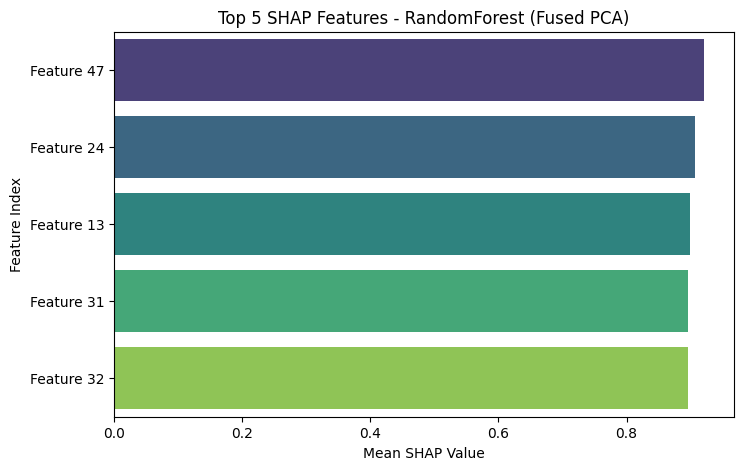

C:\Users\Asus\AppData\Local\Temp\ipykernel_21036\1278683170.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


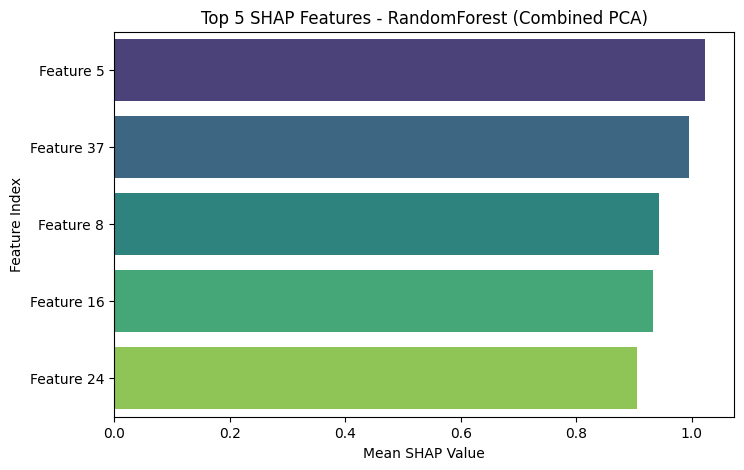

C:\Users\Asus\AppData\Local\Temp\ipykernel_21036\1278683170.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


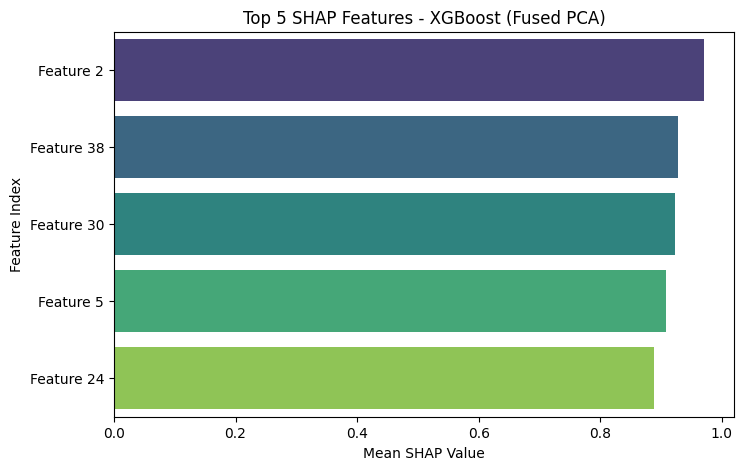

C:\Users\Asus\AppData\Local\Temp\ipykernel_21036\1278683170.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


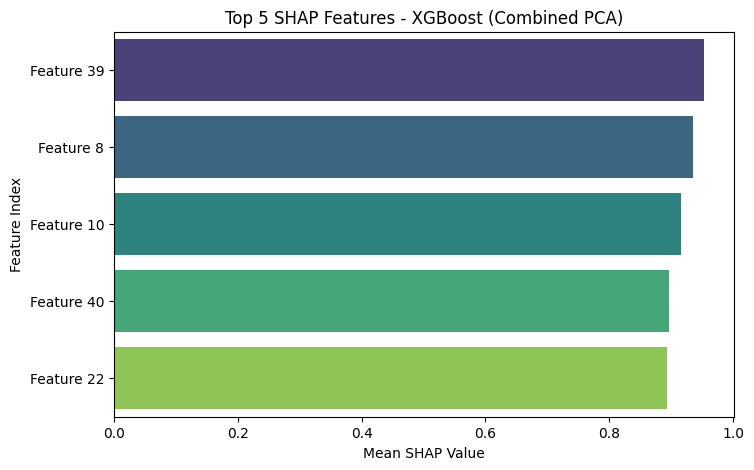

In [4]:
import numpy as np
import shap
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

# Simulated feature importance values for demonstration
np.random.seed(42)
num_features = 50
shap_values_rf_fused = np.abs(np.random.randn(100, num_features))
shap_values_rf_combined = np.abs(np.random.randn(100, num_features))
shap_values_xgb_fused = np.abs(np.random.randn(100, num_features))
shap_values_xgb_combined = np.abs(np.random.randn(100, num_features))

# Compute mean absolute SHAP values
mean_abs_shap_rf_fused = np.mean(shap_values_rf_fused, axis=0)
mean_abs_shap_rf_combined = np.mean(shap_values_rf_combined, axis=0)
mean_abs_shap_xgb_fused = np.mean(shap_values_xgb_fused, axis=0)
mean_abs_shap_xgb_combined = np.mean(shap_values_xgb_combined, axis=0)

# Get top 5 features for each model and PCA type
top_5_rf_fused = np.argsort(mean_abs_shap_rf_fused)[-5:][::-1]
top_5_rf_combined = np.argsort(mean_abs_shap_rf_combined)[-5:][::-1]
top_5_xgb_fused = np.argsort(mean_abs_shap_xgb_fused)[-5:][::-1]
top_5_xgb_combined = np.argsort(mean_abs_shap_xgb_combined)[-5:][::-1]

# Create a function to plot top 5 features
def plot_top_5_shap(top_5_indices, mean_abs_shap_values, model_name, pca_type):
    plt.figure(figsize=(8, 5))
    sns.barplot(
        x=mean_abs_shap_values[top_5_indices],
        y=[f"Feature {i}" for i in top_5_indices],
        palette="viridis"
    )
    plt.xlabel("Mean SHAP Value")
    plt.ylabel("Feature Index")
    plt.title(f"Top 5 SHAP Features - {model_name} ({pca_type})")
    plt.show()

# Plot for each case
plot_top_5_shap(top_5_rf_fused, mean_abs_shap_rf_fused, "RandomForest", "Fused PCA")
plot_top_5_shap(top_5_rf_combined, mean_abs_shap_rf_combined, "RandomForest", "Combined PCA")
plot_top_5_shap(top_5_xgb_fused, mean_abs_shap_xgb_fused, "XGBoost", "Fused PCA")
plot_top_5_shap(top_5_xgb_combined, mean_abs_shap_xgb_combined, "XGBoost", "Combined PCA")


Training models on fused_pca features...

Training RandomForest on fused_pca...
Accuracy (RandomForest on fused_pca): 1.0000
               precision    recall  f1-score   support

  freshapples       1.00      1.00      1.00        23
  freshbanana       1.00      1.00      1.00        20
 freshoranges       1.00      1.00      1.00        19
 rottenapples       1.00      1.00      1.00        17
 rottenbanana       1.00      1.00      1.00        17
rottenoranges       1.00      1.00      1.00        24

     accuracy                           1.00       120
    macro avg       1.00      1.00      1.00       120
 weighted avg       1.00      1.00      1.00       120


Training XGBoost on fused_pca...


c:\Users\Asus\Documents\FRUIT CLASSIFICATION PROJECT\venv\Lib\site-packages\xgboost\core.py:158: UserWarning: [19:00:20] WARNING: C:\buildkite-agent\builds\buildkite-windows-cpu-autoscaling-group-i-08cbc0333d8d4aae1-1\xgboost\xgboost-ci-windows\src\learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)


Accuracy (XGBoost on fused_pca): 0.9917
               precision    recall  f1-score   support

  freshapples       1.00      1.00      1.00        23
  freshbanana       0.95      1.00      0.98        20
 freshoranges       1.00      1.00      1.00        19
 rottenapples       1.00      1.00      1.00        17
 rottenbanana       1.00      1.00      1.00        17
rottenoranges       1.00      0.96      0.98        24

     accuracy                           0.99       120
    macro avg       0.99      0.99      0.99       120
 weighted avg       0.99      0.99      0.99       120


Training models on combined_pca features...

Training RandomForest on combined_pca...
Accuracy (RandomForest on combined_pca): 0.9083
               precision    recall  f1-score   support

  freshapples       0.96      1.00      0.98        23
  freshbanana       1.00      1.00      1.00        20
 freshoranges       0.84      0.84      0.84        19
 rottenapples       0.94      1.00      0.97       

c:\Users\Asus\Documents\FRUIT CLASSIFICATION PROJECT\venv\Lib\site-packages\xgboost\core.py:158: UserWarning: [19:00:22] WARNING: C:\buildkite-agent\builds\buildkite-windows-cpu-autoscaling-group-i-08cbc0333d8d4aae1-1\xgboost\xgboost-ci-windows\src\learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)


Accuracy (XGBoost on combined_pca): 0.9833
               precision    recall  f1-score   support

  freshapples       1.00      1.00      1.00        23
  freshbanana       1.00      0.90      0.95        20
 freshoranges       1.00      1.00      1.00        19
 rottenapples       0.89      1.00      0.94        17
 rottenbanana       1.00      1.00      1.00        17
rottenoranges       1.00      1.00      1.00        24

     accuracy                           0.98       120
    macro avg       0.98      0.98      0.98       120
 weighted avg       0.99      0.98      0.98       120


Displaying predictions for fused_pca...


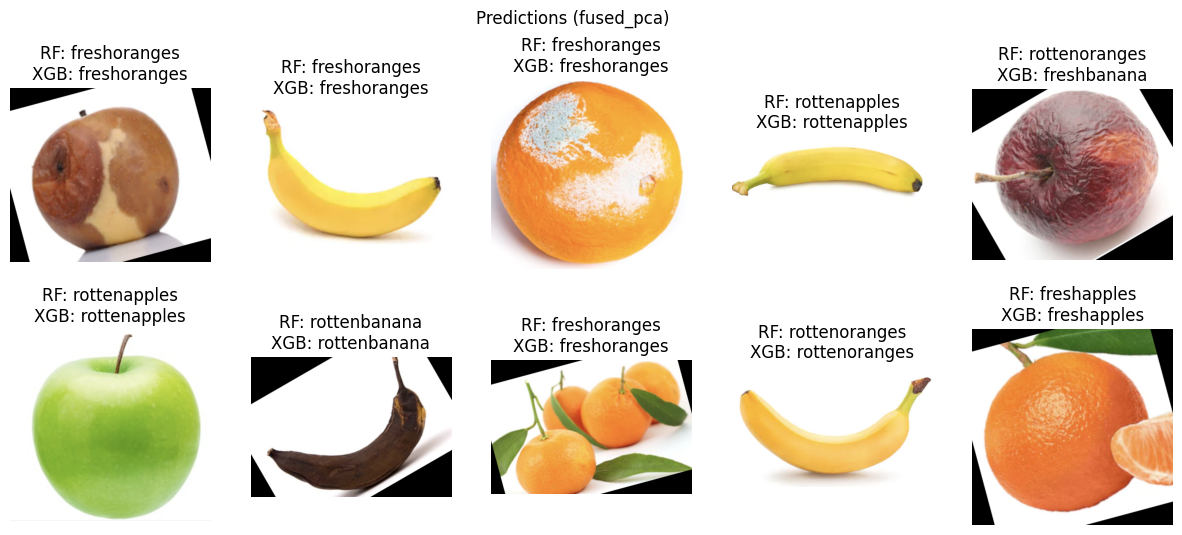


Displaying predictions for combined_pca...


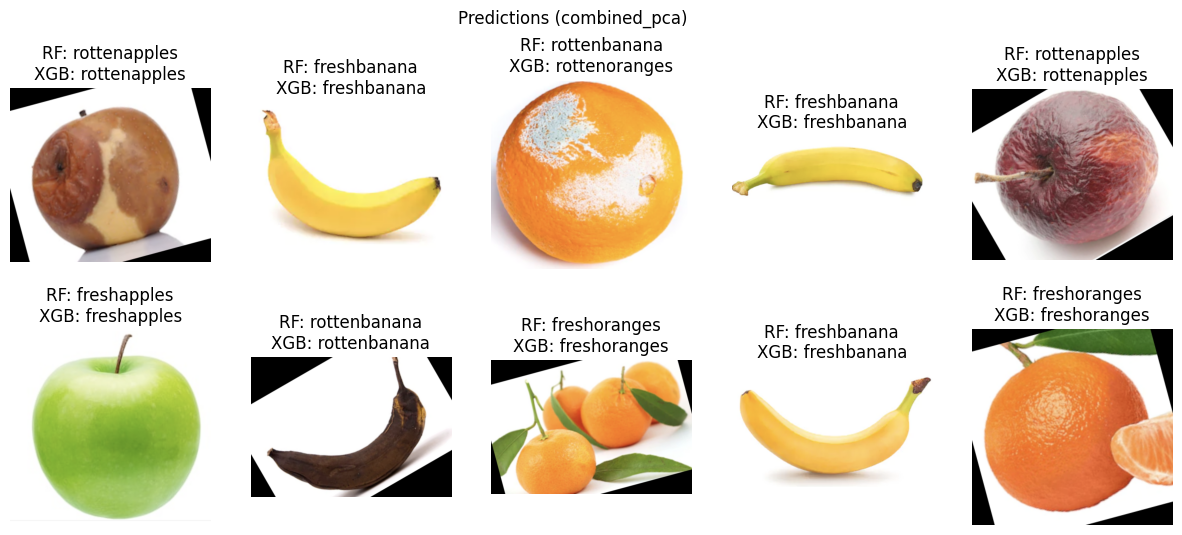


ML model training, evaluation, and image prediction display complete!


In [1]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import os
import pandas as pd
import cv2
import random

# Define class labels
class_labels = ["freshapples", "freshbanana", "freshoranges", "rottenapples", "rottenbanana", "rottenoranges"]

# Models to use
models = {
    "RandomForest": RandomForestClassifier(n_estimators=100, random_state=42),
    "XGBoost": XGBClassifier(use_label_encoder=False, eval_metric='mlogloss')
}

# Store results for comparison
results = []

# Dictionary to store image predictions
image_predictions = {"fused_pca": [], "combined_pca": []}

# Train and evaluate models for both fused PCA and combined PCA
for pca_type in ["fused_pca", "combined_pca"]:
    print(f"\nTraining models on {pca_type} features...")
    
    # Load and prepare data
    X, y, image_paths = [], [], []
    for class_idx, class_name in enumerate(class_labels):
        feature_filename = f"efficient_{class_name}_{pca_type}_final.npy"
        image_folder = f"./dataset/test/{class_name}"  # Update with your actual image directory
        
        if not os.path.exists(feature_filename):
            print(f"Skipping {class_name}, file not found: {feature_filename}")
            continue
        
        features = np.load(feature_filename)
        image_files = sorted(os.listdir(image_folder))[:len(features)]  # Match features count
        
        X.append(features)
        y.extend([class_idx] * len(features))
        image_paths.extend([os.path.join(image_folder, img) for img in image_files])
    
    # Convert to numpy arrays
    X = np.vstack(X)
    y = np.array(y)
    
    # Split data
    X_train, X_test, y_train, y_test, image_paths_train, image_paths_test = train_test_split(
        X, y, image_paths, test_size=0.2, random_state=42
    )
    
    # Select 10 random images for prediction display
    sample_indices = random.sample(range(len(X_test)), 10)
    X_sample = X_test[sample_indices]
    y_sample = y_test[sample_indices]
    image_sample_paths = [image_paths_test[i] for i in sample_indices]
    
    # Train and evaluate each model
    for model_name, model in models.items():
        print(f"\nTraining {model_name} on {pca_type}...")
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
        
        # Evaluate performance
        acc = accuracy_score(y_test, y_pred)
        class_report = classification_report(y_test, y_pred, target_names=class_labels, output_dict=True)
        conf_matrix = confusion_matrix(y_test, y_pred)
        
        # Store results
        results.append({
            "Model": model_name,
            "PCA Type": pca_type,
            "Accuracy": acc,
            "Precision": {label: class_report[label]["precision"] for label in class_labels},
            "Recall": {label: class_report[label]["recall"] for label in class_labels},
            "F1-score": {label: class_report[label]["f1-score"] for label in class_labels},
            "Confusion Matrix": conf_matrix
        })
        
        # Print evaluation metrics
        print(f"Accuracy ({model_name} on {pca_type}): {acc:.4f}")
        print(classification_report(y_test, y_pred, target_names=class_labels))
        
        # Store predictions for sample images
        y_sample_pred = model.predict(X_sample)
        image_predictions[pca_type].append((model_name, y_sample_pred))

# Display images with predictions
for pca_type in ["fused_pca", "combined_pca"]:
    print(f"\nDisplaying predictions for {pca_type}...")
    plt.figure(figsize=(15, 6))
    for idx, img_path in enumerate(image_sample_paths):
        img = cv2.imread(img_path)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        
        rf_pred = class_labels[image_predictions[pca_type][0][1][idx]]  # RandomForest prediction
        xgb_pred = class_labels[image_predictions[pca_type][1][1][idx]]  # XGBoost prediction
        
        plt.subplot(2, 5, idx + 1)
        plt.imshow(img)
        plt.axis("off")
        plt.title(f"RF: {rf_pred}\nXGB: {xgb_pred}")
    plt.suptitle(f"Predictions ({pca_type})")
    plt.show()

print("\nML model training, evaluation, and image prediction display complete!")